# Proyecto: Entendimiento de datos (P) (Entrega 1)
Astrid Lorena Roa Avila

Diana Milena González Mirke

Johan Sebastián Franco Vera

Juan Felipe Penagos Angrino


### Configuración del controlador e inicio de sesión Spark

El conector JDBC de MySQL (Connector/J 9.7.0) se descarga la primera vez en `~/.miid4103/jars` (requiere internet) y lo reutilizan los demás notebooks.

In [1]:
import os
import sys

# En la máquina virtual ya está todo instalado
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
IN_CODESPACES = os.environ.get('CODESPACES') == 'true'

if IN_COLAB or IN_CODESPACES:
    %pip install -q pyspark==4.2.0 pandas==2.3.3 numpy==2.5.3 pyarrow==25.0.1 matplotlib==3.11.2 fg-data-profiling==4.20.0 scipy==1.18.1 seaborn==0.13.2

if IN_COLAB:
    # Spark 4 requiere Java 17 o superior
    !apt-get install -y -qq openjdk-21-jdk-headless > /dev/null
    os.environ['JAVA_HOME'] = '/usr/lib/jvm/java-21-openjdk-amd64'

ENVIRONMENT = 'colab' if IN_COLAB else 'codespaces' if IN_CODESPACES else 'local'
print(f'Entorno detectado: {ENVIRONMENT}')

from pyspark.sql import SparkSession
from pyspark.sql import functions
from pyspark.sql.types import StructType
from pyspark.sql.types import FloatType, StringType, IntegerType, DateType
from pyspark.sql.functions import udf, col, length, isnan, when, count
import pyspark.sql.functions as f
from datetime import datetime
from pyspark.sql import types as t

from data_profiling import ProfileReport

import matplotlib.pyplot as plt
import numpy as np

Entorno detectado: local


In [2]:
from pathlib import Path
import urllib.request

CONNECTOR_VERSION = '9.7.0'
CONNECTOR_URL = ('https://repo1.maven.org/maven2/com/mysql/mysql-connector-j/'
                 f'{CONNECTOR_VERSION}/mysql-connector-j-{CONNECTOR_VERSION}.jar')

def obtener_jar_mysql():
    env_path = os.environ.get('CONNECTOR_J_PATH', '')
    if env_path and Path(env_path).is_file():
        return Path(env_path)
    jar = Path.home() / '.miid4103' / 'jars' / f'mysql-connector-j-{CONNECTOR_VERSION}.jar'
    if not jar.exists():
        jar.parent.mkdir(parents=True, exist_ok=True)
        print(f'Descargando MySQL Connector/J {CONNECTOR_VERSION}...')
        parcial = jar.with_suffix('.part')
        urllib.request.urlretrieve(CONNECTOR_URL, parcial)
        parcial.replace(jar)
    return jar

MYSQL_JAR = obtener_jar_mysql()
MYSQL_JAR_URI = MYSQL_JAR.as_uri()
print(f'Conector JDBC: {MYSQL_JAR}')

Conector JDBC: C:\Users\astri\.miid4103\jars\mysql-connector-j-9.7.0.jar


In [3]:
os.environ['PYSPARK_PYTHON'] = sys.executable
os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable
# Necesario en Windows si Python está en C:\Program Files
import pyspark
os.environ.setdefault('SPARK_HOME', os.path.dirname(pyspark.__file__))
# Spark 4.2 en Windows requiere HADOOP_HOME
if os.name == 'nt' and 'HADOOP_HOME' not in os.environ:
    hadoop_home = Path.home() / '.miid4103' / 'hadoop'
    (hadoop_home / 'bin').mkdir(parents=True, exist_ok=True)
    (hadoop_home / 'bin' / 'winutils.exe').touch()
    os.environ['HADOOP_HOME'] = str(hadoop_home)

# En macOS con Java de Homebrew el kernel de Jupyter no siempre encuentra Java (error JAVA_GATEWAY_EXITED)
if 'JAVA_HOME' not in os.environ and os.path.exists('/usr/libexec/java_home'):
    import subprocess
    os.environ['JAVA_HOME'] = subprocess.run(['/usr/libexec/java_home'], capture_output=True, text=True).stdout.strip()

spark = (SparkSession.builder
         .master('local[*]')
         .appName('MIID4103-NB02')
         .config('spark.driver.host', '127.0.0.1')
         .config('spark.jars', MYSQL_JAR_URI)
         .config('spark.sql.execution.arrow.pyspark.enabled', 'true')
         .config('spark.sql.shuffle.partitions', '8')
         .config('spark.ui.enabled', 'false')
         .config('spark.ui.showConsoleProgress', 'false')
         .config('spark.sql.ansi.enabled', 'false')    # comportamiento de Spark 3.5
         .getOrCreate())
spark.sparkContext.setLogLevel('ERROR')

In [4]:
db_host = '157.253.236.120'
db_port = 8080
db_user = 'DB_202615_al_roa '.strip()
db_psswd = '202626538'

if not db_user or not db_psswd:
    raise ValueError('Complete db_user y db_psswd antes de continuar')
jdbc_opciones = 'useConfigs=maxPerformance&connectTimeout=10000&socketTimeout=600000'
db_connection_string = f'jdbc:mysql://{db_host}:{db_port}/RaSaTransaccional?{jdbc_opciones}'

# En Colab, suba los archivos a /content/
PATH = '/content/' if ENVIRONMENT == 'colab' else './'

OUT = Path('/content/salidas') if ENVIRONMENT == 'colab' else Path.home() / 'MIID4103' / 'salidas'
OUT.mkdir(parents=True, exist_ok=True)

### Conexión fuente de datos

In [5]:
def obtener_dataframe_de_bd(db_connection_string, sql, db_user, db_psswd):
    df_bd = spark.read.format('jdbc')\
        .option('url', db_connection_string) \
        .option('dbtable', sql) \
        .option('user', db_user) \
        .option('password', db_psswd) \
        .option('driver', 'com.mysql.cj.jdbc.Driver') \
        .load()
    return df_bd.cache()

In [6]:
# Conexión tabla Fuente Areas De servicio
sql_FuenteAreas = 'RaSaTransaccional.FuenteAreasDeServicio_Copia_E'

# Conexión tabla Fuente condiciones de pago
sql_FuenteCondicionesPago = 'RaSaTransaccional.FuenteCondicionesDePago_Copia_E'

# Conexión tabla Fuente planes beneficio
sql_FuentePlanesBeneficio = 'RaSaTransaccional.FuentePlanesBeneficio_Copia_E'

# Conexión tabla Fuente tipos beneficio
sql_FuenteTiposBeneficio = 'RaSaTransaccional.FuenteTiposBeneficio_Copia_E'


In [7]:
FuenteAreas = obtener_dataframe_de_bd(db_connection_string, sql_FuenteAreas, db_user, db_psswd)

FuenteCondicionesPago = obtener_dataframe_de_bd(db_connection_string, sql_FuenteCondicionesPago, db_user, db_psswd)

FuentePlanesBeneficio = obtener_dataframe_de_bd(db_connection_string, sql_FuentePlanesBeneficio, db_user, db_psswd)

FuenteTiposBeneficio = obtener_dataframe_de_bd(db_connection_string, sql_FuenteTiposBeneficio, db_user, db_psswd)

In [8]:
FuenteAreas.show(5) 
FuenteCondicionesPago.show(5)
FuentePlanesBeneficio.show(5)
FuenteTiposBeneficio.show(5)

+------------------+--------------------+-------------+-----------------+----------+------------+-----+--------+-----+
|IdAreaDeServicio_T|NombreAreaDeServicio|IdGeografia_T|          Condado|    Estado|PoblacionAct| Area|Densidad|Fecha|
+------------------+--------------------+-------------+-----------------+----------+------------+-----+--------+-----+
|         100622017|New Jersey - Medi...|        34005|Burlington County|New Jersey|    464269.0|805.0|   577.0| 2017|
|         101012018|New Jersey - Medi...|        34031|   Passaic County|New Jersey|    518117.0|185.0|  2801.0| 2018|
|          10132017|BlueOptions16842F...|        12031|     Duval County|   Florida|    999935.0|774.0|  1292.0| 2017|
|         101982018|New Jersey - Medi...|        34003|    Bergen County|New Jersey|    953819.0|234.0|  4076.0| 2018|
|         102012017|New Jersey - Medi...|        34021|    Mercer County|New Jersey|    385898.0|226.0|  1708.0| 2017|
+------------------+--------------------+-------

 # Entregable 1 - Perfilamiento de datos: 

El perfilamiento describe los datos tal como llegan de la fuente: tamaño, tipos, formatos, nulos, valores distintos y distribución de cada columna de las cuatro tablas extraídas arriba (FuenteAreas, FuenteCondicionesPago, FuentePlanesBeneficio, FuenteTiposBeneficio).


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 60)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

## 1.1 Funciones de perfilamiento
Se definen funciones reutilizables para las cuatro tablas. Cada una calcula sus métricas en una sola pasada (`agg`) y devuelve un `DataFrame` de pandas para facilitar la lectura:

- `perfil_columnas`: tipo, nulos, cadenas vacías, valores distintos, mínimo, máximo y longitud de cada columna.
- `estadisticos_numericos`: media, desviación, percentiles, asimetría, curtosis, ceros y negativos de las columnas medidas.
- `frecuencias`: distribución de valores de una columna categórica.

In [10]:
def perfil_columnas(df):
    """Perfil por columna: tipo, completitud, cardinalidad, rango y longitud."""
    total = df.count()
    exprs = []
    for c, tipo in df.dtypes:
        exprs += [f.sum(col(c).isNull().cast('int')).alias(f'{c}__nulos'),
                  f.countDistinct(col(c)).alias(f'{c}__distintos'),
                  f.min(col(c)).cast('string').alias(f'{c}__min'),
                  f.max(col(c)).cast('string').alias(f'{c}__max'),
                  f.min(f.length(col(c).cast('string'))).alias(f'{c}__lmin'),
                  f.max(f.length(col(c).cast('string'))).alias(f'{c}__lmax')]
        if tipo == 'string':
            exprs.append(f.sum((f.trim(col(c)) == '').cast('int')).alias(f'{c}__vacios'))
    r = df.agg(*exprs).first().asDict()
    filas = []
    for c, tipo in df.dtypes:
        nulos, dist = r[f'{c}__nulos'], r[f'{c}__distintos']
        filas.append({'columna': c, 'tipo_spark': tipo,
                      'no_nulos': total - nulos, 'nulos': nulos, '%_nulos': round(100 * nulos / total, 2),
                      'vacios': r.get(f'{c}__vacios', 0),
                      'distintos': dist, '%_distintos': round(100 * dist / total, 2),
                      'min': r[f'{c}__min'], 'max': r[f'{c}__max'],
                      'long_min': r[f'{c}__lmin'], 'long_max': r[f'{c}__lmax']})
    return pd.DataFrame(filas).set_index('columna')


def estadisticos_numericos(df, columnas):
    """Estadísticos descriptivos de columnas numéricas (medidas, no identificadores)."""
    probs = [0.01, 0.25, 0.5, 0.75, 0.99]
    exprs = []
    for c in columnas:
        exprs += [f.count(c).alias(f'{c}__n'), f.mean(c).alias(f'{c}__media'),
                  f.stddev(c).alias(f'{c}__desv'), f.min(c).alias(f'{c}__min'),
                  f.percentile_approx(c, probs, 10000).alias(f'{c}__q'),
                  f.max(c).alias(f'{c}__max'), f.skewness(c).alias(f'{c}__asim'),
                  f.kurtosis(c).alias(f'{c}__curt'),
                  f.sum((col(c) == 0).cast('int')).alias(f'{c}__ceros'),
                  f.sum((col(c) < 0).cast('int')).alias(f'{c}__neg')]
    r = df.agg(*exprs).first().asDict()
    filas = []
    for c in columnas:
        q = r[f'{c}__q'] or [None] * 5
        filas.append({'columna': c, 'n': r[f'{c}__n'], 'media': r[f'{c}__media'], 'desv_est': r[f'{c}__desv'],
                      'min': r[f'{c}__min'], 'p01': q[0], 'p25': q[1], 'mediana': q[2], 'p75': q[3], 'p99': q[4],
                      'max': r[f'{c}__max'], 'asimetria': r[f'{c}__asim'], 'curtosis': r[f'{c}__curt'],
                      'ceros': r[f'{c}__ceros'], 'negativos': r[f'{c}__neg']})
    return pd.DataFrame(filas).set_index('columna')


def frecuencias(df, c, n=15):
    """Frecuencia absoluta y relativa de los n valores más comunes de una columna."""
    total = df.count()
    return (df.groupBy(c).count()
              .withColumn('%', f.round(100 * col('count') / total, 2))
              .orderBy(f.desc('count'), c).limit(n).toPandas())

## 1.2 Alcance y tamaño de las fuentes
Primero se dimensiona el universo de datos: número de filas y columnas, tipo de columnas. 

In [11]:
fuentes = {
    'FuenteAreasDeServicio': FuenteAreas,
    'FuenteCondicionesDePago': FuenteCondicionesPago,
    'FuentePlanesBeneficio': FuentePlanesBeneficio,
    'FuenteTiposBeneficio': FuenteTiposBeneficio,
}
pandas_fuentes = {nombre: df.toPandas() for nombre, df in fuentes.items()}

alcance = []
for nombre, df in fuentes.items():
    tipos = [t for _, t in df.dtypes]
    alcance.append({'tabla': nombre, 'filas': df.count(), 'columnas': len(df.columns),
                    'cols_numericas': sum(t in ('int', 'bigint', 'float', 'double') or t.startswith('decimal') for t in tipos),
                    'cols_texto': sum(t == 'string' for t in tipos),
                    'celdas': df.count() * len(df.columns)})
alcance = pd.DataFrame(alcance).set_index('tabla')
alcance['%_filas'] = (100 * alcance['filas'] / alcance['filas'].sum()).round(2)
alcance.loc['TOTAL'] = alcance.sum()
alcance.astype({c: int for c in ['filas', 'columnas', 'cols_numericas', 'cols_texto', 'celdas']})

,filas,columnas,cols_numericas,cols_texto,celdas,%_filas
tabla,,,,,,
FuenteAreasDeServicio,188815,9,6,3,1699335,83.65
FuenteCondicionesDePago,31,3,1,2,93,0.01
FuentePlanesBeneficio,36036,11,9,2,396396,15.96
FuenteTiposBeneficio,849,9,2,7,7641,0.38
TOTAL,225731,32,18,14,2103465,100.00


In [12]:
tablas_sql = "'FuenteAreasDeServicio_Copia_E','FuenteCondicionesDePago_Copia_E','FuentePlanesBeneficio_Copia_E','FuenteTiposBeneficio_Copia_E'"
meta_columnas = obtener_dataframe_de_bd(db_connection_string, f"""(
    SELECT TABLE_NAME AS tabla, ORDINAL_POSITION AS pos, COLUMN_NAME AS columna,
           COLUMN_TYPE AS tipo_mysql, IS_NULLABLE AS acepta_nulos, COLUMN_KEY AS llave
    FROM information_schema.COLUMNS
    WHERE TABLE_SCHEMA = 'RaSaTransaccional' AND TABLE_NAME IN ({tablas_sql})) t""", db_user, db_psswd)

tipos_spark = pd.DataFrame([(n.replace('Fuente', 'Fuente', 1), c, t) for n, df in fuentes.items() for c, t in df.dtypes],
                           columns=['tabla_nb', 'columna', 'tipo_spark'])
meta_col_pd = meta_columnas.orderBy('tabla', 'pos').toPandas()
meta_col_pd['tabla_nb'] = meta_col_pd['tabla'].str.replace('_Copia_E', '', regex=False)
diccionario = meta_col_pd.merge(tipos_spark, on=['tabla_nb', 'columna'], how='left')
pd.set_option('display.max_rows', 60)
diccionario[['tabla_nb', 'pos', 'columna', 'tipo_mysql', 'tipo_spark', 'acepta_nulos', 'llave']]

,tabla_nb,pos,columna,tipo_mysql,tipo_spark,acepta_nulos,llave
0,FuenteAreasDeServicio,1,IdAreaDeServicio_T,int,int,YES,
1,FuenteAreasDeServicio,2,NombreAreaDeServicio,text,string,YES,
2,FuenteAreasDeServicio,3,IdGeografia_T,int,int,YES,
3,FuenteAreasDeServicio,4,Condado,text,string,YES,
4,FuenteAreasDeServicio,5,Estado,text,string,YES,
5,FuenteAreasDeServicio,6,PoblacionAct,float,float,YES,
6,FuenteAreasDeServicio,7,Area,float,float,YES,
7,FuenteAreasDeServicio,8,Densidad,float,float,YES,
8,FuenteAreasDeServicio,9,Fecha,int,int,YES,
9,FuenteCondicionesDePago,1,IdCondicionesDePago_T,int,int,YES,


In [13]:
# Resumen del diccionario: llaves declaradas, columnas que aceptan nulos y equivalencia de tipos MySQL/Spark
equivalencia = {'int': 'int', 'bigint': 'bigint', 'float': 'float', 'text': 'string'}
diccionario['tipo_equivalente'] = diccionario['tipo_mysql'].map(equivalencia) == diccionario['tipo_spark']
diccionario.groupby('tabla_nb').agg(
    columnas=('columna', 'count'),
    columnas_con_llave=('llave', lambda s: (s.str.strip() != '').sum()),
    columnas_que_aceptan_nulos=('acepta_nulos', lambda s: (s == 'YES').sum()),
    tipos_mysql=('tipo_mysql', lambda s: ', '.join(sorted(s.unique()))))

,columnas,columnas_con_llave,columnas_que_aceptan_nulos,tipos_mysql
tabla_nb,,,,
FuenteAreasDeServicio,9,0,9,"float, int, text"
FuenteCondicionesDePago,3,0,3,"int, text"
FuentePlanesBeneficio,11,0,11,"bigint, int, text"
FuenteTiposBeneficio,9,0,9,"int, text"


**Alcance y tamaño de las fuentes**

- Son **4 tablas con 225.731 filas, 32 columnas y 2.103.465 celdas**.
- **FuenteAreasDeServicio tiene el 83,65% de las filas (188.815)** FuentePlanesBeneficio tiene el 15,96% de las filas (36.036). FuenteTiposBeneficio (849 filas) y FuenteCondicionesDePago (31 filas) suman menos del 0,4%.
- `filas_estimadas` de `information_schema` difiere del conteo real en FuenteAreasDeServicio (174.510 frente a 188.815) y en FuentePlanesBeneficio (35.268 frente a 36.036). El conteo exacto es el de la primera tabla.

**Tipos de datos y restricciones**
- **Ninguna de las 32 columnas tiene llave declarada** (`columnas_con_llave` = 0) y **todas aceptan nulos** (`columnas_que_aceptan_nulos` = total de columnas).
- En todas las columnas el tipo que lee Spark equivale al tipo de MySQL (`tipo_spark_equivalente` = True). Los textos están definidos como `text`.
- `Fecha` es `int` en FuenteAreasDeServicio y FuenteTiposBeneficio, y `text` en FuentePlanesBeneficio.
- `IdTipoBeneficio_T` e `IdAreaDeServicio_T` son `bigint` en FuentePlanesBeneficio e `int` en FuenteTiposBeneficio y FuenteAreasDeServicio.
- Las cinco banderas de FuenteTiposBeneficio (`EsEHB`, `EstaCubiertaPorSeguro`, `TieneLimiteCuantitativo`, `ExcluidoDelDesembolsoMaximoDentroDeLaRed`, `ExcluidoDelDesembolsoMaximoFueraDeLaRed`) son `text`. `PoblacionAct`, `Area` y `Densidad` son `float`.

## 1.3 FuenteAreasDeServicio
### 1.3.1 Estructura y muestra

In [14]:
FuenteAreas.printSchema()
FuenteAreas.show(5, truncate=False)

root
 |-- IdAreaDeServicio_T: integer (nullable = true)
 |-- NombreAreaDeServicio: string (nullable = true)
 |-- IdGeografia_T: integer (nullable = true)
 |-- Condado: string (nullable = true)
 |-- Estado: string (nullable = true)
 |-- PoblacionAct: float (nullable = true)
 |-- Area: float (nullable = true)
 |-- Densidad: float (nullable = true)
 |-- Fecha: integer (nullable = true)

+------------------+---------------------------------------------+-------------+-----------------+----------+------------+-----+--------+-----+
|IdAreaDeServicio_T|NombreAreaDeServicio                         |IdGeografia_T|Condado          |Estado    |PoblacionAct|Area |Densidad|Fecha|
+------------------+---------------------------------------------+-------------+-----------------+----------+------------+-----+--------+-----+
|100622017         |New Jersey - Medical91661NJ2340003-0520174859|34005        |Burlington County|New Jersey|464269.0    |805.0|577.0   |2017 |
|101012018         |New Jersey - Medi

### 1.3.2 Perfil por columna

In [15]:
perfil_columnas(FuenteAreas)

,tipo_spark,no_nulos,nulos,%_nulos,vacios,distintos,%_distintos,min,max,long_min,long_max
columna,,,,,,,,,,,
IdAreaDeServicio_T,int,182527,6288,3.33,0,5409,2.86,12018,117872018,5,9
NombreAreaDeServicio,string,188815,0,0.00,0,5412,2.87,AZ Statewide12303AZ0010001-01201774,Wyoming11269WY0080014-00201710379,27,80
IdGeografia_T,int,182437,6378,3.38,0,4251,2.25,1001,168135,4,6
Condado,string,188815,0,0.00,0,1398,0.74,Abbeville County,Ziebach County,5,28
Estado,string,188815,0,0.00,0,35,0.02,Alabama,Wyoming,4,14
PoblacionAct,float,188815,0,0.00,0,3729,1.97,82.0,4.72803E10,4,10
Area,float,186408,2407,1.27,0,1957,1.04,-24707.0,88824.0,3,8
Densidad,float,186408,2407,1.27,0,495,0.26,0.0,14946.0,3,7
Fecha,int,188815,0,0.00,0,3,0.00,1800,2018,4,4


### 1.3.3 Estadísticos de las variables numéricas
Los `Id` se tratan como identificadores (no tiene sentido promediarlos); los estadísticos se calculan solo sobre las medidas.

In [16]:
estadisticos_numericos(FuenteAreas, ['PoblacionAct', 'Area', 'Densidad'])

,n,media,desv_est,min,p01,p25,mediana,p75,p99,max,asimetria,curtosis,ceros,negativos
columna,,,,,,,,,,,,,,
PoblacionAct,188815,"41,479,590.39","594,383,589.18",82.00,"1,508.00","12,538.00","30,885.00","110,686.00","668,649,984.00","47,280,300,032.00",32.63,"1,632.83",0,0
Area,186408,770.95,"1,263.49","-24,707.00",-805.00,400.00,575.00,870.00,"4,882.00","88,824.00",27.90,"1,722.30",0,6177
Densidad,186408,276.10,851.32,0.00,1.00,20.00,51.00,170.00,"2,939.00","14,946.00",9.74,136.03,769,0


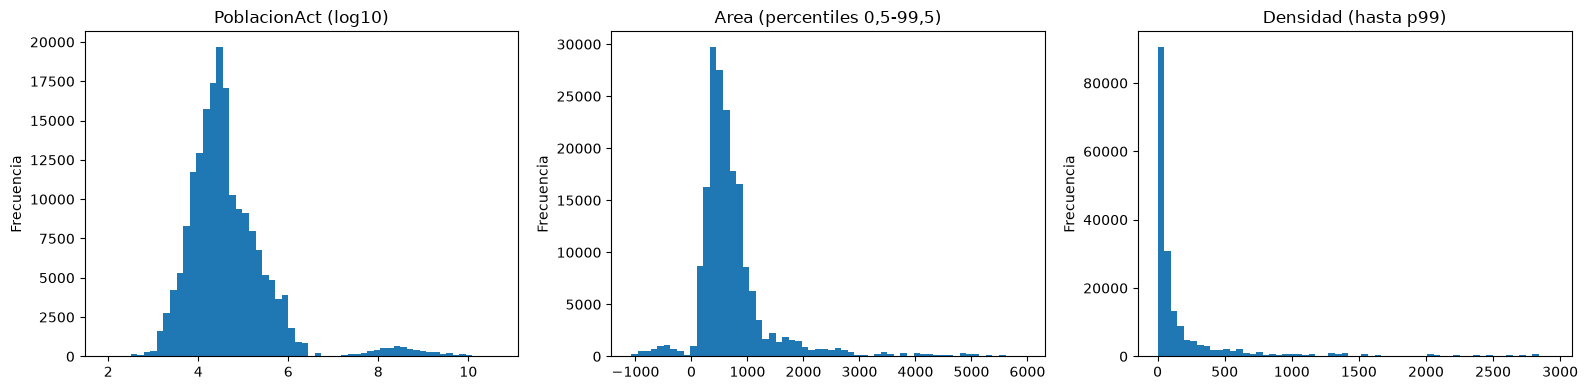

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
pd_a = pandas_fuentes['FuenteAreasDeServicio']
axes[0].hist(np.log10(pd_a['PoblacionAct'].dropna().clip(lower=1)), bins=60)
axes[0].set_title('PoblacionAct (log10)')
axes[1].hist(pd_a['Area'].dropna(), bins=60, range=(pd_a['Area'].quantile(0.005), pd_a['Area'].quantile(0.995)))
axes[1].set_title('Area (percentiles 0,5-99,5)')
axes[2].hist(pd_a['Densidad'].dropna(), bins=60, range=(0, pd_a['Densidad'].quantile(0.99)))
axes[2].set_title('Densidad (hasta p99)')
for ax in axes:
    ax.set_ylabel('Frecuencia')
plt.tight_layout()
plt.show()

### 1.3.4 Variables categóricas y temporales

In [18]:
frecuencias(FuenteAreas, 'Fecha')

,Fecha,count,%
0,2017,99211,52.54
1,2018,83322,44.13
2,1800,6282,3.33


In [19]:
frecuencias(FuenteAreas, 'Estado', 40)

,Estado,count,%
0,Indiana,14150,7.49
1,Missouri,13913,7.37
2,Georgia,13822,7.32
3,Wisconsin,12543,6.64
4,Michigan,11598,6.14
5,Texas,11261,5.96
6,South Dakota,10930,5.79
7,Kansas,10824,5.73
8,Kentucky,10571,5.60
9,Oklahoma,8183,4.33


In [20]:
# Sufijo del nombre del condado (County, Parish, Borough, ...)
sufijo = FuenteAreas.withColumn('sufijo_condado', f.regexp_extract('Condado', r'(\S+)$', 1))
frecuencias(sufijo, 'sufijo_condado')

,sufijo_condado,count,%
0,County,185460,98.22
1,City,2690,1.42
2,Parish,337,0.18
3,Borough,205,0.11
4,Wrangell,25,0.01
5,Juneau,23,0.01
6,Yakutat,20,0.01
7,Skagway,19,0.01
8,Anchorage,18,0.01
9,Sitka,13,0.01


In [21]:
# Estados en los que aparecen los condados que no terminan en "County"
(sufijo.filter(col('sufijo_condado') != 'County')
       .groupBy('sufijo_condado').agg(f.count('*').alias('filas'),
                                      f.array_sort(f.collect_set('Estado')).alias('estados'))
       .orderBy(f.desc('filas')).toPandas())

,sufijo_condado,filas,estados
0,City,2690,"[Missouri, Virginia]"
1,Parish,337,[Louisiana]
2,Borough,205,[Alaska]
3,Wrangell,25,[Alaska]
4,Juneau,23,[Alaska]
5,Yakutat,20,[Alaska]
6,Skagway,19,[Alaska]
7,Anchorage,18,[Alaska]
8,Sitka,13,[Alaska]
9,Bedford,5,[Virginia]


### 1.3.5 Formatos de identificadores y textos

In [22]:
# Estados asociados a cada longitud de IdGeografia_T
(FuenteAreas.withColumn('digitos', f.length(col('IdGeografia_T').cast('string')))
    .groupBy('digitos').agg(f.count('*').alias('filas'), f.countDistinct('Estado').alias('estados_distintos'),
                            f.slice(f.array_sort(f.collect_set('Estado')), 1, 8).alias('primeros_estados'))
    .orderBy('digitos').toPandas())

,digitos,filas,estados_distintos,primeros_estados
0,NaN,6378,35,"[Alabama, Alaska, Arizona, Arkansas, Delaware, Florida, ..."
1,4.00,2024,4,"[Alabama, Alaska, Arizona, Arkansas]"
2,5.00,166700,33,"[Arizona, Arkansas, Delaware, Florida, Georgia, Hawaii, ..."
3,6.00,13713,16,"[New Jersey, New Mexico, North Carolina, North Dakota, O..."


In [23]:
# Descomposición de NombreAreaDeServicio: texto + código con formato de IdPlan_T + 4 dígitos + consecutivo
regex_nombre = r'^(.*?)(\d{5}[A-Z]{2}\d{7}-\d{2})(\d{4})(\d+)$'
FuenteAreas.select(
    f.count('*').alias('filas'),
    f.sum(col('NombreAreaDeServicio').rlike(regex_nombre).cast('int')).alias('cumplen_estructura')).show()

nombres = FuenteAreas.select('NombreAreaDeServicio', 'Fecha',
    f.regexp_extract('NombreAreaDeServicio', regex_nombre, 1).alias('texto'),
    f.regexp_extract('NombreAreaDeServicio', regex_nombre, 2).alias('codigo_plan'),
    f.regexp_extract('NombreAreaDeServicio', regex_nombre, 3).alias('anio_en_nombre'),
    f.regexp_extract('NombreAreaDeServicio', regex_nombre, 4).alias('consecutivo'))
nombres.show(5, truncate=False)
frecuencias(nombres, 'anio_en_nombre')

+------+------------------+
| filas|cumplen_estructura|
+------+------------------+
|188815|            188815|
+------+------------------+

+---------------------------------------------+-----+--------------------+-----------------+--------------+-----------+
|NombreAreaDeServicio                         |Fecha|texto               |codigo_plan      |anio_en_nombre|consecutivo|
+---------------------------------------------+-----+--------------------+-----------------+--------------+-----------+
|New Jersey - Medical91661NJ2340003-0520174859|2017 |New Jersey - Medical|91661NJ2340003-05|2017          |4859       |
|New Jersey - Medical91661NJ2340003-0520184611|2018 |New Jersey - Medical|91661NJ2340003-05|2018          |4611       |
|BlueOptions16842FL0070128-032017260          |2017 |BlueOptions         |16842FL0070128-03|2017          |260        |
|New Jersey - Medical91661NJ2340003-0520184591|2018 |New Jersey - Medical|91661NJ2340003-05|2018          |4591       |
|New Jersey - Medic

,anio_en_nombre,count,%
0,2017,102681,54.38
1,2018,86134,45.62


In [24]:
# Granularidad: cuántas filas hay por área de servicio y cuántos condados cubre cada una
gran = (FuenteAreas.filter(col('IdAreaDeServicio_T').isNotNull())
        .groupBy('IdAreaDeServicio_T')
        .agg(f.count('*').alias('filas'), f.countDistinct('Condado', 'Estado').alias('condados'),
             f.countDistinct('Estado').alias('estados')))
gran.select([f.percentile_approx(c, [0.0, 0.25, 0.5, 0.75, 1.0], 10000).alias(c) for c in ['filas', 'condados', 'estados']]).toPandas().T \
    .rename(columns={0: '[min, p25, mediana, p75, max]'})

,"[min, p25, mediana, p75, max]"
filas,"[1, 11, 22, 46, 237]"
condados,"[1, 7, 14, 29, 154]"
estados,"[1, 1, 1, 1, 1]"


**Observaciones del perfilamiento – FuenteAreasDeServicio**

- **Contenido de una fila:** un condado (`Condado`, `Estado`, `IdGeografia_T`) asociado a un área de servicio (`IdAreaDeServicio_T`, `NombreAreaDeServicio`) y a un año (`Fecha`), con `PoblacionAct`, `Area` y `Densidad`.
- **Cardinalidad:** 5.409 `IdAreaDeServicio_T` distintos, 1.398 nombres de condado, 35 estados y 3 valores de `Fecha`. Cada área de servicio aparece en un solo estado (`estados` máx = 1) y cubre entre 1 y 154 condados (mediana 14). Tiene entre 1 y 237 filas (mediana 22).
- **Completitud:**
  - `IdAreaDeServicio_T`: 6.288 nulos (3,33%).
  - `IdGeografia_T`: 6.378 nulos (3,38%).
  - `Area` y `Densidad`: 2.407 nulos cada una (1,27%).
  - Las columnas de texto no tienen nulos ni cadenas vacías.
- **Variables numéricas:**
  - `PoblacionAct` va de 82 a 4,73·10¹⁰. La mediana es 30.885, el p75 110.686 y el p99 6,69·10⁸; la media (41.479.590) está muy por encima de la mediana. Asimetría 32,63 y curtosis 1.632,83.
  - `Area` va de -24.707 a 88.824, con mediana 575. Hay **6.177 valores negativos** y el p01 es -805.
  - `Densidad` va de 0 a 14.946, con mediana 51, 769 ceros y ningún valor negativo.
- **Variables categóricas:**
  - `Fecha`: 2017 (52,54%), 2018 (44,13%) y **1800 (6.282 filas; 3,33%)**.
  - `Estado`: los más frecuentes son Indiana (7,49%), Missouri (7,37%) y Georgia (7,32%); los menos frecuentes, Hawaii y Delaware (0,02%).
  - `Condado`: el 98,22% termina en *County*. Los otros sufijos son *City* (Missouri y Virginia), *Parish* (Louisiana), *Borough* (Alaska), *Bedford* (Virginia) y nombres de Alaska sin sufijo (Wrangell, Juneau, Yakutat, Skagway, Anchorage, Sitka).
- **Formatos:**
  - `IdAreaDeServicio_T` tiene de 5 a 9 dígitos. Sus últimos 4 dígitos son siempre 2017 (52,56%) o 2018 (44,11%); el resto son nulos.
  - `IdGeografia_T` tiene 4 dígitos (1,07%, solo en Alabama, Alaska, Arizona y Arkansas), 5 dígitos (88,29%, en 33 estados) o 6 dígitos (7,26%, en 16 estados).
  - `NombreAreaDeServicio` (27 a 80 caracteres) cumple en las 188.815 filas la estructura *texto + código con el formato de `IdPlan_T` (`99999AA9999999-99`) + 4 dígitos + consecutivo*. Ejemplo: `BlueOptions` + `16842FL0070128-03` + `2017` + `260`. Los 4 dígitos son 2017 (54,38%) o 2018 (45,62%).

## 1.4 FuenteCondicionesDePago
### 1.4.1 Estructura y contenido completo
Al ser un catálogo pequeño se muestra completo.

In [25]:
FuenteCondicionesPago.printSchema()
FuenteCondicionesPago.orderBy('IdCondicionesDePago_T').show(50, truncate=False)

root
 |-- IdCondicionesDePago_T: integer (nullable = true)
 |-- Descripcion: string (nullable = true)
 |-- Tipo: string (nullable = true)

+---------------------+--------------------------------+-------------+
|IdCondicionesDePago_T|Descripcion                     |Tipo         |
+---------------------+--------------------------------+-------------+
|9                    |No Charge                       |Coseguridad  |
|17                   |Copay per Day after deductible  |Copago       |
|18                   |No Charge after deductible      |Coseguro     |
|27                   |Coinsurance after deductible    |Coseguro     |
|27                   |Coinsurance after deductible    |Coseguro     |
|34                   |Not Applicable                  |Copagado     |
|36                   |Not Applicable                  |Coseguro     |
|45                   |Coinsurance                     |Coseguro     |
|45                   |Coinsurance                     |Coseguro     |
|51      

### 1.4.2 Perfil por columna

In [26]:
perfil_columnas(FuenteCondicionesPago)

,tipo_spark,no_nulos,nulos,%_nulos,vacios,distintos,%_distintos,min,max,long_min,long_max
columna,,,,,,,,,,,
IdCondicionesDePago_T,int,31,0,0.00,0,23,74.19,9,714,1,3
Descripcion,string,31,0,0.00,0,17,54.84,Coinsurance,Not Applicable,5,32
Tipo,string,31,0,0.00,0,6,19.35,Copagado,SinTipoCopago,3,13


### 1.4.3 Distribución de valores

In [27]:
frecuencias(FuenteCondicionesPago, 'Tipo')

,Tipo,count,%
0,Copago,19,61.29
1,Coseguro,7,22.58
2,NaN,2,6.45
3,Copagado,1,3.23
4,Coseguridad,1,3.23
5,SinTipoCopago,1,3.23


In [28]:
frecuencias(FuenteCondicionesPago, 'Descripcion', 20)

,Descripcion,count,%
0,Coinsurance,3,9.68
1,Copay per Stay,3,9.68
2,Copay per Stay after deductible,3,9.68
3,No Charge,3,9.68
4,No Charge after deductible,3,9.68
5,Coinsurance after deductible,2,6.45
6,Copay,2,6.45
7,Copay per Day with deductible,2,6.45
8,Not Applicable,2,6.45
9,Copay after deductible,1,3.23


In [29]:
# Componentes de la descripción: tipo de cargo y relación con el deducible
comp = (FuenteCondicionesPago
        .withColumn('cargo', f.regexp_extract('Descripcion', r'^(Copay per Day|Copay per Stay|Copay|Coinsurance|No Charge|Not Applicable)', 1))
        .withColumn('deducible', f.regexp_extract('Descripcion', r'(after|before|with) deductible$', 1)))
comp.groupBy('cargo', 'deducible').count().orderBy('cargo', 'deducible').toPandas()

,cargo,deducible,count
0,Coinsurance,,3
1,Coinsurance,after,2
2,Copay,,2
3,Copay,after,1
4,Copay,before,1
5,Copay,with,1
6,Copay per Day,,1
7,Copay per Day,after,1
8,Copay per Day,before,1
9,Copay per Day,with,2


**Observaciones del perfilamiento – FuenteCondicionesDePago**

- **Contenido de una fila:** una condición de pago (`IdCondicionesDePago_T`) con su `Descripcion` y su `Tipo`.
- **Cardinalidad:** 31 filas con **23 Id distintos** (entre 9 y 714), 17 descripciones y 6 tipos.
- **Completitud:** no hay nulos ni cadenas vacías, pero `Tipo` contiene **2 veces el texto `NaN`**.
- **Distribución de `Tipo`:** `Copago` (61,29%), `Coseguro` (22,58%), `NaN` (6,45%), y `Copagado`, `Coseguridad` y `SinTipoCopago` (3,23% cada uno).
- **Formato de `Descripcion`:** todas las descripciones se componen de un tipo de cargo (*Copay*, *Copay per Day*, *Copay per Stay*, *Coinsurance*, *No Charge* o *Not Applicable*), seguido o no de una relación con el deducible (*after*, *before* o *with deductible*).

## 1.5 FuentePlanesBeneficio
### 1.5.1 Estructura y muestra

In [30]:
FuentePlanesBeneficio.printSchema()
FuentePlanesBeneficio.show(5, truncate=False)

root
 |-- IdTipoBeneficio_T: long (nullable = true)
 |-- IdAreaDeServicio_T: long (nullable = true)
 |-- IdCondicionDePagoCopago_T: integer (nullable = true)
 |-- IdCondicionDePagoCoseguro_T: integer (nullable = true)
 |-- IdNivelServicio_T: integer (nullable = true)
 |-- IdPlan_T: string (nullable = true)
 |-- Fecha: string (nullable = true)
 |-- IdProveedor_T: integer (nullable = true)
 |-- valorCopago: integer (nullable = true)
 |-- valorCoseguro: integer (nullable = true)
 |-- cantidadLimite: integer (nullable = true)

+-----------------+------------------+-------------------------+---------------------------+-----------------+-----------------+----------+-------------+-----------+-------------+--------------+
|IdTipoBeneficio_T|IdAreaDeServicio_T|IdCondicionDePagoCopago_T|IdCondicionDePagoCoseguro_T|IdNivelServicio_T|IdPlan_T         |Fecha     |IdProveedor_T|valorCopago|valorCoseguro|cantidadLimite|
+-----------------+------------------+-------------------------+-----------------

### 1.5.2 Perfil por columna

In [31]:
perfil_columnas(FuentePlanesBeneficio)

,tipo_spark,no_nulos,nulos,%_nulos,vacios,distintos,%_distintos,min,max,long_min,long_max
columna,,,,,,,,,,,
IdTipoBeneficio_T,bigint,33950,2086,5.79,0,285,0.79,5,2110,1,4
IdAreaDeServicio_T,bigint,33995,2041,5.66,0,6496,18.03,12018,235734036,5,9
IdCondicionDePagoCopago_T,int,36036,0,0.00,0,14,0.04,17,238,2,3
IdCondicionDePagoCoseguro_T,int,36036,0,0.00,0,5,0.01,9,45,1,2
IdNivelServicio_T,int,36036,0,0.00,0,3,0.01,1,3,1,1
IdPlan_T,string,36036,0,0.00,2053,393,1.09,,99969OH0080069-00,0,17
Fecha,string,36036,0,0.00,0,5,0.01,1920-12-31,"Dec 31,2018",10,11
IdProveedor_T,int,36036,0,0.00,0,125,0.35,10207,99969,5,5
valorCopago,int,36036,0,0.00,0,49,0.14,0,3500,1,4


### 1.5.3 Estadísticos de las variables numéricas

In [32]:
estadisticos_numericos(FuentePlanesBeneficio, ['valorCopago', 'valorCoseguro', 'cantidadLimite'])

,n,media,desv_est,min,p01,p25,mediana,p75,p99,max,asimetria,curtosis,ceros,negativos
columna,,,,,,,,,,,,,,
valorCopago,36036,9.78,100.41,0,0,0,0,0,250,3500,19.87,522.89,34060,0
valorCoseguro,36036,24.29,36.96,0,0,0,0,50,100,100,1.26,-0.00,21962,0
cantidadLimite,5465,129.33,951.28,1,1,1,25,40,2500,30000,20.60,565.67,0,0


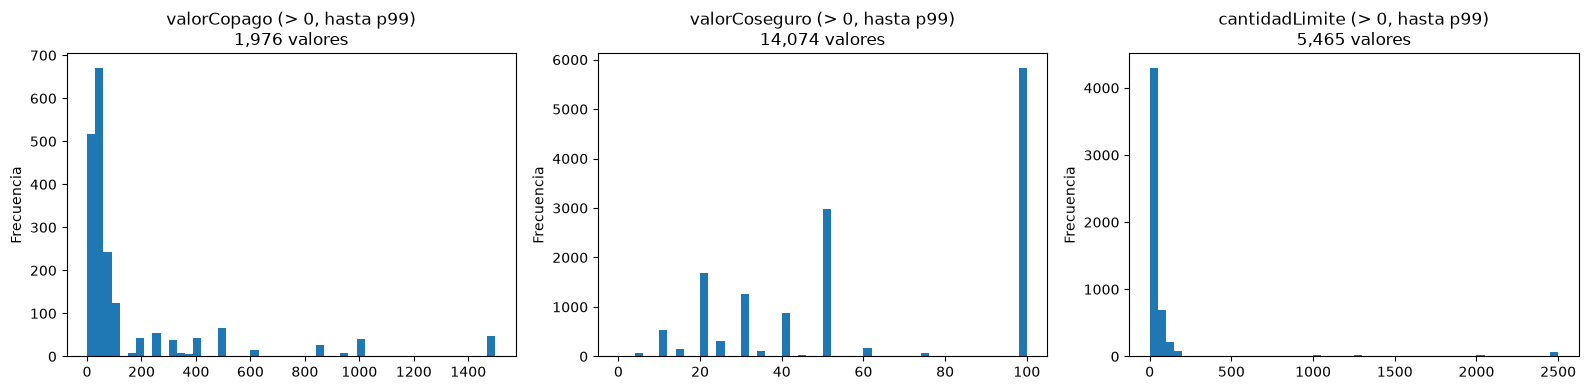

In [33]:
pd_p = pandas_fuentes['FuentePlanesBeneficio']
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ['valorCopago', 'valorCoseguro', 'cantidadLimite']):
    s = pd_p[c].dropna()
    s = s[s > 0]
    ax.hist(s, bins=50, range=(0, s.quantile(0.99)) if len(s) else None)
    ax.set_title(f'{c} (> 0, hasta p99)\n{len(s):,} valores')
    ax.set_ylabel('Frecuencia')
plt.tight_layout()
plt.show()

In [34]:
# Valores más frecuentes de las medidas (muestran si son valores "redondos" o continuos)
for c in ['valorCopago', 'valorCoseguro', 'cantidadLimite']:
    print(c)
    display(frecuencias(FuentePlanesBeneficio, c, 10))

valorCopago


,valorCopago,count,%
0,0,34060,94.52
1,50,250,0.69
2,30,160,0.44
3,20,136,0.38
4,10,115,0.32
5,35,114,0.32
6,100,91,0.25
7,40,88,0.24
8,15,87,0.24
9,60,78,0.22


valorCoseguro


,valorCoseguro,count,%
0,0,21962,60.94
1,100,5836,16.19
2,50,2976,8.26
3,20,1679,4.66
4,30,1267,3.52
5,40,883,2.45
6,10,526,1.46
7,25,316,0.88
8,60,166,0.46
9,15,149,0.41


cantidadLimite


,cantidadLimite,count,%
0,NaN,30571,84.83
1,1.00,1725,4.79
2,30.00,637,1.77
3,60.00,580,1.61
4,35.00,418,1.16
5,20.00,366,1.02
6,2.00,290,0.80
7,25.00,216,0.60
8,40.00,175,0.49
9,100.00,150,0.42


### 1.5.4 Variables categóricas y llaves foráneas

In [35]:
frecuencias(FuentePlanesBeneficio, 'IdNivelServicio_T')

,IdNivelServicio_T,count,%
0,1,12045,33.42
1,3,12028,33.38
2,2,11963,33.20


In [36]:
frecuencias(FuentePlanesBeneficio, 'IdCondicionDePagoCopago_T')

,IdCondicionDePagoCopago_T,count,%
0,238,18123,50.29
1,34,16364,45.41
2,51,612,1.70
3,207,325,0.90
4,153,290,0.80
5,170,124,0.34
6,102,50,0.14
7,187,49,0.14
8,68,31,0.09
9,136,25,0.07


In [37]:
frecuencias(FuentePlanesBeneficio, 'IdCondicionDePagoCoseguro_T')

,IdCondicionDePagoCoseguro_T,count,%
0,45,22762,63.16
1,27,8354,23.18
2,36,3785,10.50
3,18,664,1.84
4,9,471,1.31


In [38]:
frecuencias(FuentePlanesBeneficio, 'IdProveedor_T', 10)

,IdProveedor_T,count,%
0,33602,3759,10.43
1,67243,1657,4.60
2,41921,1581,4.39
3,36096,1395,3.87
4,40047,1308,3.63
5,37833,1292,3.59
6,87571,1048,2.91
7,28162,1042,2.89
8,66252,931,2.58
9,38166,921,2.56


### 1.5.5 Formatos: `Fecha` (texto) e `IdPlan_T`

In [39]:
frecuencias(FuentePlanesBeneficio, 'Fecha')

,Fecha,count,%
0,2017-12-31,16134,44.77
1,2018-12-31,15794,43.83
2,1920-12-31,2052,5.69
3,"Dec 31,2017",1029,2.86
4,"Dec 31,2018",1027,2.85


In [40]:
# Filas con cada valor de Fecha según si IdPlan_T está vacío
(FuentePlanesBeneficio.groupBy('Fecha', (f.trim(col('IdPlan_T')) == '').alias('IdPlan_T_vacio'))
    .count().orderBy('Fecha', 'IdPlan_T_vacio').toPandas())

,Fecha,IdPlan_T_vacio,count
0,1920-12-31,False,2052
1,2017-12-31,False,15106
2,2017-12-31,True,1028
3,2018-12-31,False,14769
4,2018-12-31,True,1025
5,"Dec 31,2017",False,1029
6,"Dec 31,2018",False,1027


In [41]:
# Componentes de IdPlan_T: primeros 5 dígitos frente a IdProveedor_T, y las 2 letras
planes_no_vacios = FuentePlanesBeneficio.filter(f.trim(col('IdPlan_T')) != '')
planes_no_vacios.select(
    f.count('*').alias('filas_IdPlan_no_vacio'),
    f.sum((f.substring('IdPlan_T', 1, 5) == col('IdProveedor_T').cast('string')).cast('int')).alias('prefijo_igual_a_IdProveedor_T')).show()
frecuencias(planes_no_vacios.withColumn('letras_IdPlan_T', f.substring('IdPlan_T', 6, 2)), 'letras_IdPlan_T', 40)

+---------------------+-----------------------------+
|filas_IdPlan_no_vacio|prefijo_igual_a_IdProveedor_T|
+---------------------+-----------------------------+
|                33983|                        33983|
+---------------------+-----------------------------+



,letras_IdPlan_T,count,%
0,TX,5215,15.35
1,WI,3279,9.65
2,MI,2753,8.10
3,IL,2247,6.61
4,LA,1893,5.57
5,GA,1855,5.46
6,VA,1838,5.41
7,OH,1535,4.52
8,FL,1460,4.30
9,NJ,1138,3.35


In [42]:
# Granularidad: filas (beneficios) por plan y planes por proveedor
por_plan = FuentePlanesBeneficio.filter(f.trim(col('IdPlan_T')) != '').groupBy('IdPlan_T').count()
por_prov = FuentePlanesBeneficio.groupBy('IdProveedor_T').agg(f.countDistinct('IdPlan_T').alias('planes'))
print('Planes distintos:', por_plan.count(), '| Proveedores distintos:', por_prov.count())
pd.DataFrame({
    'beneficios_por_plan': por_plan.select(f.percentile_approx('count', [0.0, 0.25, 0.5, 0.75, 1.0], 10000)).first()[0],
    'planes_por_proveedor': por_prov.select(f.percentile_approx('planes', [0.0, 0.25, 0.5, 0.75, 1.0], 10000)).first()[0],
}, index=['min', 'p25', 'mediana', 'p75', 'max'])

Planes distintos: 392 | Proveedores distintos: 125


,beneficios_por_plan,planes_por_proveedor
min,1,1
p25,7,2
mediana,13,2
p75,218,4
max,1240,38


**Observaciones del perfilamiento – FuentePlanesBeneficio**

- **Contenido de una fila:** un tipo de beneficio (`IdTipoBeneficio_T`) dentro de un plan (`IdPlan_T`) de un proveedor (`IdProveedor_T`), en un área de servicio (`IdAreaDeServicio_T`), un nivel de servicio (`IdNivelServicio_T`) y una `Fecha`. Incluye sus condiciones de pago (`IdCondicionDePagoCopago_T`, `IdCondicionDePagoCoseguro_T`) y los valores `valorCopago`, `valorCoseguro` y `cantidadLimite`.
- **Cardinalidad:** 392 planes, 125 proveedores, 285 tipos de beneficio, 6.496 áreas de servicio y 3 niveles de servicio (33,42%, 33,38% y 33,20% de las filas).
  - Cada plan tiene entre 1 y 1.240 filas (mediana 13, p75 218).
  - Cada proveedor tiene entre 1 y 38 planes (mediana 2).
  - El proveedor 33602 tiene el 10,43% de las filas.
- **Completitud:**
  - `IdTipoBeneficio_T`: 2.086 nulos (5,79%).
  - `IdAreaDeServicio_T`: 2.041 nulos (5,66%).
  - `IdPlan_T`: ningún nulo, pero **2.053 cadenas vacías (5,70%)**.
  - `cantidadLimite`: **30.571 nulos (84,83%)**.
- **Variables numéricas:**
  - `valorCopago` va de 0 a 3.500. Es 0 en el **94,52%** de las filas (mediana y p75 = 0, p99 = 250), con asimetría 19,87. Los valores distintos de 0 más frecuentes son 50, 30, 20, 10 y 35.
  - `valorCoseguro` va de 0 a 100 y es 0 en el 60,94% de las filas. Los valores distintos de 0 más frecuentes son 100 (16,19%), 50 (8,26%) y 20 (4,66%).
  - `cantidadLimite` va de 1 a 30.000, con mediana 25, p99 2.500 y asimetría 20,60.
- **Llaves hacia los catálogos:**
  - `IdCondicionDePagoCopago_T` toma 14 valores: el 238 (*Copay* en el catálogo) tiene el 50,29% de las filas y el 34 (*Not Applicable*) el 45,41%.
  - `IdCondicionDePagoCoseguro_T` toma 5 valores: el 45 (*Coinsurance*) tiene el 63,16%.
- **Formatos:**
  - `Fecha` es texto con 5 valores y dos formatos: `yyyy-MM-dd` (94,29%) y `MMM dd,yyyy` (5,71%). Los valores son `2017-12-31` (44,77%), `2018-12-31` (43,83%), **`1920-12-31` (5,69%)**, `Dec 31,2017` (2,86%) y `Dec 31,2018` (2,85%).
  - Los 2.053 `IdPlan_T` vacíos están en las fechas `2017-12-31` (1.028) y `2018-12-31` (1.025). Ninguno coincide con las fechas `1920-12-31` ni con el formato `MMM dd,yyyy`.
  - Todos los `IdPlan_T` no vacíos tienen el formato `99999AA9999999-99` (17 caracteres). En las 33.983 filas, los 5 primeros dígitos son iguales a `IdProveedor_T`. Las 2 letras toman 35 valores (TX 15,35%, WI 9,65%, MI 8,10%...).
  - `IdAreaDeServicio_T` tiene de 5 a 9 dígitos, igual que en FuenteAreasDeServicio.

## 1.6 FuenteTiposBeneficio
### 1.6.1 Estructura y muestra

In [43]:
FuenteTiposBeneficio.printSchema()
FuenteTiposBeneficio.show(5, truncate=False)

root
 |-- IdTipoBeneficio_T: integer (nullable = true)
 |-- Nombre: string (nullable = true)
 |-- UnidadDelLimite: string (nullable = true)
 |-- EsEHB: string (nullable = true)
 |-- EstaCubiertaPorSeguro: string (nullable = true)
 |-- TieneLimiteCuantitativo: string (nullable = true)
 |-- ExcluidoDelDesembolsoMaximoDentroDeLaRed: string (nullable = true)
 |-- ExcluidoDelDesembolsoMaximoFueraDeLaRed: string (nullable = true)
 |-- Fecha: integer (nullable = true)

+-----------------+-----------------------------+------------------------+-----+---------------------+-----------------------+----------------------------------------+---------------------------------------+-----+
|IdTipoBeneficio_T|Nombre                       |UnidadDelLimite         |EsEHB|EstaCubiertaPorSeguro|TieneLimiteCuantitativo|ExcluidoDelDesembolsoMaximoDentroDeLaRed|ExcluidoDelDesembolsoMaximoFueraDeLaRed|Fecha|
+-----------------+-----------------------------+------------------------+-----+---------------------+---

### 1.6.2 Perfil por columna

In [44]:
perfil_columnas(FuenteTiposBeneficio)

,tipo_spark,no_nulos,nulos,%_nulos,vacios,distintos,%_distintos,min,max,long_min,long_max
columna,,,,,,,,,,,
IdTipoBeneficio_T,int,849,0,0.00,0,178,20.97,5,1055,1,4
Nombre,string,849,0,0.00,0,178,20.97,Abortion for Which Public Funding is Prohibited,X-rays and Diagnostic Imaging,4,63
UnidadDelLimite,string,849,0,0.00,559,63,7.42,,Visit(s) per year,0,93
EsEHB,string,849,0,0.00,0,3,0.35,No,Yes,2,4
EstaCubiertaPorSeguro,string,849,0,0.00,0,3,0.35,False,Yes,2,5
TieneLimiteCuantitativo,string,849,0,0.00,0,4,0.47,Nein,Yes,2,4
ExcluidoDelDesembolsoMaximoDentroDeLaRed,string,849,0,0.00,0,3,0.35,Algunas veces,Yes,2,13
ExcluidoDelDesembolsoMaximoFueraDeLaRed,string,849,0,0.00,0,2,0.24,No,Yes,2,3
Fecha,int,849,0,0.00,0,2,0.24,2017,2018,4,4


### 1.6.3 Variables categóricas (banderas)
Las columnas `Es...`, `Esta...`, `Tiene...` y `Excluido...` son banderas; se revisa qué valores toman y con qué frecuencia.

In [45]:
banderas = ['EsEHB', 'EstaCubiertaPorSeguro', 'TieneLimiteCuantitativo',
            'ExcluidoDelDesembolsoMaximoDentroDeLaRed', 'ExcluidoDelDesembolsoMaximoFueraDeLaRed']
total_tipos = FuenteTiposBeneficio.count()
tabla_banderas = {}
for c in banderas:
    vc = FuenteTiposBeneficio.groupBy(c).count().toPandas()
    vc[c] = vc[c].fillna('<NULL>')
    tabla_banderas[c] = vc.set_index(c)['count']
pd.DataFrame(tabla_banderas).fillna(0).astype(int)

,EsEHB,EstaCubiertaPorSeguro,TieneLimiteCuantitativo,ExcluidoDelDesembolsoMaximoDentroDeLaRed,ExcluidoDelDesembolsoMaximoFueraDeLaRed
Algunas veces,0,0,0,2,0
False,0,8,0,0,0
Nein,0,0,24,0,0
No,399,98,542,787,516
Si,0,0,12,0,0
True,20,0,0,0,0
Yes,430,743,271,60,333


In [46]:
frecuencias(FuenteTiposBeneficio, 'Fecha')

,Fecha,count,%
0,2017,672,79.15
1,2018,177,20.85


In [47]:
# Filas frente a identificadores distintos
FuenteTiposBeneficio.select(f.count('*').alias('filas'),
                            f.countDistinct('IdTipoBeneficio_T').alias('IdTipoBeneficio_T_distintos'),
                            f.countDistinct('IdTipoBeneficio_T', 'Fecha').alias('combinaciones_Id_Fecha')).show()

+-----+---------------------------+----------------------+
|filas|IdTipoBeneficio_T_distintos|combinaciones_Id_Fecha|
+-----+---------------------------+----------------------+
|  849|                        178|                   218|
+-----+---------------------------+----------------------+



In [48]:
frecuencias(FuenteTiposBeneficio, 'UnidadDelLimite', 25)

,UnidadDelLimite,count,%
0,,559,65.84
1,Visit(s) per Year,64,7.54
2,Visit(s) per Benefit Period,31,3.65
3,Days per Year,14,1.65
4,Days per Benefit Period,13,1.53
5,Visit(s) per YearVisit(s) per YearVisit(s) per Year,11,1.30
6,Exam(s) per Year,10,1.18
7,Item(s) per Year,10,1.18
8,Dollars per Year,9,1.06
9,Visit(s) per 6 Months,7,0.82


In [49]:
# UnidadDelLimite vacía según TieneLimiteCuantitativo
(FuenteTiposBeneficio.groupBy('TieneLimiteCuantitativo')
    .agg(f.count('*').alias('filas'),
         f.sum((f.trim(col('UnidadDelLimite')) == '').cast('int')).alias('UnidadDelLimite_vacia'))
    .orderBy(f.desc('filas')).toPandas())

,TieneLimiteCuantitativo,filas,UnidadDelLimite_vacia
0,No,542,522
1,Yes,271,13
2,Nein,24,24
3,Si,12,0


In [50]:
# Longitud de los nombres de beneficio
FuenteTiposBeneficio.select(f.length('Nombre').alias('long_nombre')).summary('count', 'min', '25%', '50%', '75%', 'max').show()
frecuencias(FuenteTiposBeneficio, 'Nombre', 10)

+-------+-----------+
|summary|long_nombre|
+-------+-----------+
|  count|        849|
|    min|          4|
|    25%|         18|
|    50%|         24|
|    75%|         29|
|    max|         63|
+-------+-----------+



,Nombre,count,%
0,Dental Check-Up for Children,29,3.42
1,Skilled Nursing Facility,26,3.06
2,Orthodontia - Child,21,2.47
3,Routine Eye Exam (Adult),20,2.36
4,Hearing Aids,19,2.24
5,Private-Duty Nursing,19,2.24
6,Routine Eye Exam for Children,19,2.24
7,Eye Glasses for Children,18,2.12
8,Chiropractic Care,17,2.00
9,Nutritional Counseling,17,2.00


**Observaciones del perfilamiento – FuenteTiposBeneficio**

- **Contenido de una fila:** un tipo de beneficio (`IdTipoBeneficio_T`, `Nombre`) en un año (`Fecha`), con la unidad de su límite y cinco banderas.
- **Cardinalidad:** **849 filas, 178 Id distintos (y 178 nombres) y 218 combinaciones de Id + `Fecha`**. `Fecha` es 2017 en el 79,15% de las filas y 2018 en el 20,85%.
- **Completitud:** no hay nulos. `UnidadDelLimite` está **vacía en 559 filas (65,84%)**. Según `TieneLimiteCuantitativo`, está vacía en:
  - 522 de 542 filas con `No`;
  - 24 de 24 con `Nein`;
  - 13 de 271 con `Yes`;
  - 0 de 12 con `Si`.
- **Banderas (texto):**
  - `EsEHB`: Yes (430), No (399), True (20).
  - `EstaCubiertaPorSeguro`: Yes (743), No (98), False (8).
  - `TieneLimiteCuantitativo`: No (542), Yes (271), Nein (24), Si (12).
  - `ExcluidoDelDesembolsoMaximoDentroDeLaRed`: No (787), Yes (60), Algunas veces (2).
  - `ExcluidoDelDesembolsoMaximoFueraDeLaRed`: No (516), Yes (333).
- **Formato de `UnidadDelLimite`:** tiene 63 valores distintos, de la forma `<unidad> per <periodo>` (p. ej. *Visit(s) per Year*, *Days per Benefit Period*). Aparecen variaciones de mayúsculas (*Visit(s) per Year* y *Visit(s) per year*) y valores repetidos varias veces dentro del mismo texto (*Visit(s) per YearVisit(s) per YearVisit(s) per Year*). La longitud llega a 93 caracteres.
- **Otros formatos:** `IdTipoBeneficio_T` tiene de 1 a 4 dígitos (de 5 a 1.055; el 82,57% tiene 3 dígitos). `Nombre` tiene de 4 a 63 caracteres (mediana 24).

## 1.7 Relaciones entre las fuentes
Se identifican las columnas que conectan las tablas y el rango de años que cubre cada una (el detalle de integridad referencial se evalúa en calidad de datos).

In [51]:
relaciones = pd.DataFrame([
    ('FuentePlanesBeneficio.IdAreaDeServicio_T', 'FuenteAreasDeServicio.IdAreaDeServicio_T'),
    ('FuentePlanesBeneficio.IdTipoBeneficio_T', 'FuenteTiposBeneficio.IdTipoBeneficio_T'),
    ('FuentePlanesBeneficio.IdCondicionDePagoCopago_T', 'FuenteCondicionesDePago.IdCondicionesDePago_T'),
    ('FuentePlanesBeneficio.IdCondicionDePagoCoseguro_T', 'FuenteCondicionesDePago.IdCondicionesDePago_T'),
], columns=['columna_origen', 'columna_destino'])

def perfil_llave(ref):
    tabla, c = ref.split('.')
    r = fuentes[tabla].agg(f.countDistinct(c), f.min(c), f.max(c)).first()
    return pd.Series({'distintos': r[0], 'min': r[1], 'max': r[2]})

pd.concat([relaciones,
           relaciones['columna_origen'].apply(perfil_llave).add_suffix('_origen'),
           relaciones['columna_destino'].apply(perfil_llave).add_suffix('_destino')], axis=1)

,columna_origen,columna_destino,distintos_origen,min_origen,max_origen,distintos_destino,min_destino,max_destino
0,FuentePlanesBeneficio.IdAreaDeServicio_T,FuenteAreasDeServicio.IdAreaDeServicio_T,6496,12018,235734036,5409,12018,117872018
1,FuentePlanesBeneficio.IdTipoBeneficio_T,FuenteTiposBeneficio.IdTipoBeneficio_T,285,5,2110,178,5,1055
2,FuentePlanesBeneficio.IdCondicionDePagoCopago_T,FuenteCondicionesDePago.IdCondicionesDePago_T,14,17,238,23,9,714
3,FuentePlanesBeneficio.IdCondicionDePagoCoseguro_T,FuenteCondicionesDePago.IdCondicionesDePago_T,5,9,45,23,9,714


In [52]:
anios = pd.DataFrame({
    'FuenteAreasDeServicio': FuenteAreas.groupBy('Fecha').count().toPandas().set_index('Fecha')['count'],
    'FuenteTiposBeneficio': FuenteTiposBeneficio.groupBy('Fecha').count().toPandas().set_index('Fecha')['count'],
    'FuentePlanesBeneficio (año del texto)': FuentePlanesBeneficio
        .groupBy(f.regexp_extract('Fecha', r'(\d{4})', 1).cast('int').alias('Fecha')).count()
        .toPandas().set_index('Fecha')['count'],
}).fillna(0).astype(int).sort_index()
anios

,FuenteAreasDeServicio,FuenteTiposBeneficio,FuentePlanesBeneficio (año del texto)
Fecha,,,
1800,6282,0,0
1920,0,0,2052
2017,99211,672,17163
2018,83322,177,16821


**Columnas que conectan las fuentes:**
- `IdAreaDeServicio_T` toma 6.496 valores en FuentePlanesBeneficio (máximo 235.734.036) y 5.409 en FuenteAreasDeServicio (máximo 117.872.018).
- `IdTipoBeneficio_T` toma 285 valores en FuentePlanesBeneficio (máximo 2.110) y 178 en FuenteTiposBeneficio (máximo 1.055).
- Las condiciones de copago (14 valores, de 17 a 238) y de coseguro (5 valores, de 9 a 45) de FuentePlanesBeneficio están dentro del rango del catálogo (23 valores, de 9 a 714).

**Cobertura temporal:** las tres tablas con año tienen 2017 y 2018. Además, FuenteAreasDeServicio tiene 6.282 filas con 1800 y FuentePlanesBeneficio 2.052 filas con 1920. FuenteCondicionesDePago no tiene columna de fecha.


## 1.8 Resumen del perfilamiento

| Tabla | Filas | Columnas | % de filas | Una fila contiene |
|---|---:|---:|---:|---|
| FuenteAreasDeServicio | 188.815 | 9 | 83,65 | condado + área de servicio + año, con población, área y densidad |
| FuenteCondicionesDePago | 31 | 3 | 0,01 | condición de pago con descripción y tipo |
| FuentePlanesBeneficio | 36.036 | 11 | 15,96 | tipo de beneficio + plan + área + nivel + fecha, con condiciones y valores de pago |
| FuenteTiposBeneficio | 849 | 9 | 0,38 | tipo de beneficio + año, con unidad del límite y banderas |

**Observaciones que pasan al análisis de calidad:**

1. **Restricciones:** no hay llaves declaradas y todas las columnas aceptan nulos. Hay más filas que identificadores: FuenteCondicionesDePago tiene 31 filas para 23 Id, y FuenteTiposBeneficio 849 filas para 218 combinaciones Id + año.
2. **Faltantes:**
   - nulos en `IdAreaDeServicio_T`, `IdGeografia_T`, `Area`, `Densidad`, `IdTipoBeneficio_T` y `cantidadLimite`;
   - cadenas vacías en `IdPlan_T` y `UnidadDelLimite`;
   - el texto `NaN` en `Tipo`.
3. **Tipos y formatos:**
   - `Fecha` es `int` en dos tablas y `text` con dos formatos en FuentePlanesBeneficio.
   - Las banderas usan Yes/No, True/False, Si/Nein y "Algunas veces".
   - `Tipo` tiene 6 valores distintos.
   - `UnidadDelLimite` tiene diferencias de mayúsculas y textos repetidos.
4. **Rangos:** años 1800 y 1920, 6.177 áreas negativas, `PoblacionAct` de hasta 4,73·10¹⁰ e `IdGeografia_T` de 4, 5 y 6 dígitos.
5. **Llaves entre fuentes:** FuentePlanesBeneficio tiene más valores distintos y máximos mayores que sus catálogos en `IdAreaDeServicio_T` e `IdTipoBeneficio_T`.

# Entregable 2 - Análisis de calidad de datos:
La calidad de los datos consiste en validar la idoneidad de los datos analizando varias dimensiones:
- **Completitud**: datos que no existen o no se conocen (nulos, vacíos o marcadores como `NaN`).
- **Unicidad**: registros idénticos, o registros con la misma llave pero valores distintos.
- **Validez**: a nivel de formato y de sentido de los datos (dominios, rangos, signos).
- **Consistencia**: coherencia del dato al interior de una fila, entre filas de la misma fuente y entre fuentes.


In [53]:
def contar_vacios(df):
    """Nulos, textos vacíos y textos 'NaN' por columna."""
    total = df.count()
    resumen = []
    for c, tipo in df.dtypes:
        nulos = df.filter(col(c).isNull()).count()
        vacios = df.filter(f.trim(col(c)) == '').count() if tipo == 'string' else 0
        texto_nan = df.filter(f.lower(f.trim(col(c))) == 'nan').count() if tipo == 'string' else 0
        faltantes = nulos + vacios + texto_nan
        resumen.append((c, nulos, vacios, texto_nan, round(100 * faltantes / total, 2)))
    return spark.createDataFrame(resumen, ['columna', 'nulos', 'vacios', 'texto_NaN', 'pct_faltante'])

def cardinalidad(df):
    """Valores distintos por columna y su porcentaje sobre el total de filas."""
    total = df.count()
    resumen = [(c, df.select(c).distinct().count()) for c in df.columns]
    return spark.createDataFrame([(c, n, round(100 * n / total, 2)) for c, n in resumen],
                                 ['columna', 'distintos', 'pct_distintos'])

def registrar(res, nombre, df_casos, total):
    casos = df_casos.count()
    res.append((nombre, casos, total, round(casos / total * 100, 2) if total else None))

def mostrar_resultados(res):
    spark.createDataFrame(res, ['chequeo', 'casos', 'sobre_total', '%']).show(truncate=False)

## 2.1 FuenteAreasDeServicio


### Unicidad

In [54]:
total_areas = FuenteAreas.count()
distintas_areas = FuenteAreas.distinct().count()
print('Total de registros:', total_areas)
print('Registros únicos:', distintas_areas)
print('Filas duplicadas exactas:', total_areas - distintas_areas)
print('IdAreaDeServicio_T distintos:', FuenteAreas.select('IdAreaDeServicio_T').distinct().count())

Total de registros: 188815
Registros únicos: 145242
Filas duplicadas exactas: 43573
IdAreaDeServicio_T distintos: 5410


Hay **43.573 filas completamente duplicadas (23,1%)**; quedan 145.242 registros únicos y 5.410 áreas de servicio distintas.

Una fila representa un condado cubierto por un área de servicio, por eso `IdAreaDeServicio_T` se repite. La llave natural que se revisa es **IdAreaDeServicio_T + Condado + Estado**: sin contar las filas idénticas, cada llave debería aparecer una sola vez.

In [55]:
llave_areas = ['IdAreaDeServicio_T', 'Condado', 'Estado']
llaves_rep = (FuenteAreas.distinct().filter(col('IdAreaDeServicio_T').isNotNull())
              .groupBy(llave_areas).count().filter('count > 1'))
print('Llaves con más de una versión distinta del registro:', llaves_rep.count())
ejemplo = llaves_rep.orderBy(f.desc('count')).limit(1)
FuenteAreas.distinct().join(ejemplo.drop('count'), on=llave_areas).show(truncate=False)

Llaves con más de una versión distinta del registro: 23263
+------------------+----------------+-------+----------------------------------------+-------------+------------+-----+--------+-----+
|IdAreaDeServicio_T|Condado         |Estado |NombreAreaDeServicio                    |IdGeografia_T|PoblacionAct|Area |Densidad|Fecha|
+------------------+----------------+-------+----------------------------------------+-------------+------------+-----+--------+-----+
|93552017          |Habersham County|Georgia|QHP Service Area83761GA0040022-022017950|13137        |46774.0     |278.0|168.0   |2017 |
|93552017          |Habersham County|Georgia|QHP Service Area83761GA0040022-022017950|39411        |46774.0     |278.0|168.0   |2017 |
+------------------+----------------+-------+----------------------------------------+-------------+------------+-----+--------+-----+



Aun sin las filas idénticas, **23.263 llaves** IdArea + Condado + Estado tienen más de una versión del registro. En el ejemplo la única diferencia es `IdGeografia_T` (13137 y 39411) para el mismo condado: hay que preguntar al negocio cuál es el valor correcto.

### Completitud

In [56]:
contar_vacios(FuenteAreas).show(truncate=False)

+--------------------+-----+------+---------+------------+
|columna             |nulos|vacios|texto_NaN|pct_faltante|
+--------------------+-----+------+---------+------------+
|IdAreaDeServicio_T  |6288 |0     |0        |3.33        |
|NombreAreaDeServicio|0    |0     |0        |0.0         |
|IdGeografia_T       |6378 |0     |0        |3.38        |
|Condado             |0    |0     |0        |0.0         |
|Estado              |0    |0     |0        |0.0         |
|PoblacionAct        |0    |0     |0        |0.0         |
|Area                |2407 |0     |0        |1.27        |
|Densidad            |2407 |0     |0        |1.27        |
|Fecha               |0    |0     |0        |0.0         |
+--------------------+-----+------+---------+------------+



In [57]:
cardinalidad(FuenteAreas).show(truncate=False)

+--------------------+---------+-------------+
|columna             |distintos|pct_distintos|
+--------------------+---------+-------------+
|IdAreaDeServicio_T  |5410     |2.87         |
|NombreAreaDeServicio|5412     |2.87         |
|IdGeografia_T       |4252     |2.25         |
|Condado             |1398     |0.74         |
|Estado              |35       |0.02         |
|PoblacionAct        |3729     |1.97         |
|Area                |1958     |1.04         |
|Densidad            |496      |0.26         |
|Fecha               |3        |0.0          |
+--------------------+---------+-------------+



**Completitud:** `IdAreaDeServicio_T` tiene 6.288 nulos (3,33%), `IdGeografia_T` 6.378 (3,38%), `Area` y `Densidad` 2.407 cada una (1,27%). No hay textos vacíos ni `NaN`.

**Cardinalidad:** ninguna columna supera el 50% de valores distintos. `Estado` tiene 35 valores y `Fecha` solo 3.

### Validez

In [58]:
FuenteAreas.groupBy('Fecha').count().orderBy('Fecha').show()
print('Fecha fuera de 2017/2018:', FuenteAreas.filter(~col('Fecha').isin(2017, 2018)).count())
print('Area negativa o cero:', FuenteAreas.filter(col('Area') <= 0).count())
print('Densidad negativa:', FuenteAreas.filter(col('Densidad') < 0).count())
print('Densidad igual a cero:', FuenteAreas.filter(col('Densidad') == 0).count())
print('PoblacionAct negativa o cero:', FuenteAreas.filter(col('PoblacionAct') <= 0).count())
print('IdAreaDeServicio_T que no termina en 2017/2018:',
      FuenteAreas.filter(~f.substring(col('IdAreaDeServicio_T').cast('string'), -4, 4).isin('2017', '2018')).count())
# IdGeografia_T: código de estado (1-2 dígitos) + condado (3 dígitos), máximo 5 dígitos
print('IdGeografia_T con más de 5 dígitos:', FuenteAreas.filter(col('IdGeografia_T') > 99999).count())

+-----+-----+
|Fecha|count|
+-----+-----+
| 1800| 6282|
| 2017|99211|
| 2018|83322|
+-----+-----+

Fecha fuera de 2017/2018: 6282
Area negativa o cero: 6177
Densidad negativa: 0
Densidad igual a cero: 769
PoblacionAct negativa o cero: 0
IdAreaDeServicio_T que no termina en 2017/2018: 0
IdGeografia_T con más de 5 dígitos: 13713


In [59]:
FuenteAreas.filter(col('Area') <= 0).select('Condado', 'Estado', 'Area').show(5)
FuenteAreas.filter(col('IdGeografia_T') > 99999).select('IdGeografia_T', 'Condado', 'Estado').show(5)

+---------------+--------------+------+
|        Condado|        Estado|  Area|
+---------------+--------------+------+
|Florence County|     Wisconsin|-488.0|
|   Rowan County|North Carolina|-524.0|
| Tarrant County|         Texas|-864.0|
| Decatur County|       Indiana|-373.0|
|   Bacon County|       Georgia|-285.0|
+---------------+--------------+------+
only showing top 5 rows
+-------------+-----------------+-------------+
|IdGeografia_T|          Condado|       Estado|
+-------------+-----------------+-------------+
|       162225|Pocahontas County|West Virginia|
|       144819|   Kleberg County|        Texas|
|       105081|   Lincoln County|   New Mexico|
|       162189|    Monroe County|West Virginia|
|       138063|  Campbell County| South Dakota|
+-------------+-----------------+-------------+
only showing top 5 rows


**Validez:**
- **6.282 filas con `Fecha` = 1800**, un valor que no es válido. Todos los `IdAreaDeServicio_T` terminan en 2017 o 2018, así que el año de esas filas se podría recuperar a partir del Id.
- **6.177 filas con `Area` negativa.** En el ejemplo de consistencia (Duval County) aparece 774 y -774 para el mismo condado, lo que sugiere un error de signo. Hay que confirmarlo con el negocio.
- **13.713 filas con `IdGeografia_T` de más de 5 dígitos**, que no corresponden a un código estado + condado.
- No hay densidades ni poblaciones negativas. Las 769 filas con `Densidad` = 0 corresponden a condados con menos de 0,5 habitantes por unidad de área (la densidad está redondeada), así que no se consideran un error.

Diagramas de caja para ver la distribución y los valores extremos de las variables numéricas (población en escala logarítmica):

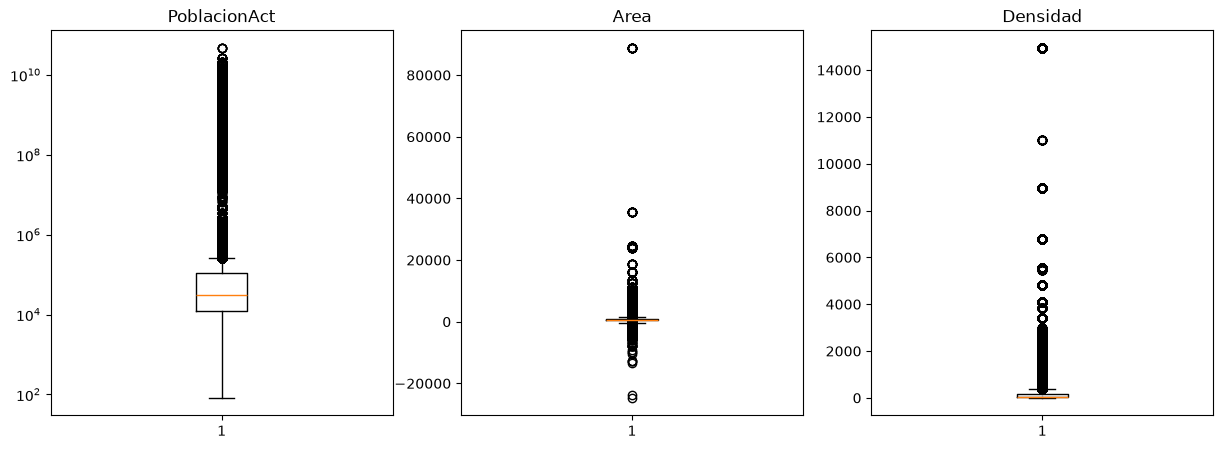

In [60]:
%matplotlib inline
pd_areas = FuenteAreas.select('PoblacionAct', 'Area', 'Densidad').toPandas()
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, c in zip(axes, ['PoblacionAct', 'Area', 'Densidad']):
    ax.boxplot(pd_areas[c].dropna())
    ax.set_title(c)
axes[0].set_yscale('log')
plt.show()

In [61]:
print('Top 10 PoblacionAct:')
FuenteAreas.select('Condado', 'Estado', 'PoblacionAct', 'Fecha').distinct().orderBy(f.desc('PoblacionAct')).show(10)

Top 10 PoblacionAct:
+-----------------+--------+------------+-----+
|          Condado|  Estado|PoblacionAct|Fecha|
+-----------------+--------+------------+-----+
|    Harris County|   Texas|  4.72803E10| 2018|
|Miami-Dade County| Florida|  2.66278E10| 2017|
|    Dallas County|   Texas|  2.58605E10| 2017|
|    Dallas County|   Texas|  2.58605E10| 2018|
|   Tarrant County|   Texas|  2.12648E10| 2018|
|   Tarrant County|   Texas|  2.12648E10| 2017|
|     Bexar County|   Texas|  2.02824E10| 2017|
|   Broward County| Florida|  1.93098E10| 2017|
|   Broward County| Florida|  1.93098E10| 2018|
|     Wayne County|Michigan|  1.77482E10| 2017|
+-----------------+--------+------------+-----+
only showing top 10 rows


El diagrama de caja de `PoblacionAct` (escala logarítmica) muestra valores extremos. Los 10 valores más altos son del orden de 10¹⁰ (por ejemplo, Harris County, Texas: 4,72·10¹⁰), más que la población mundial, así que **no son válidos**. En el ejemplo de consistencia, Duval County aparece con 999.935 y con 9,99935·10⁹, es decir 10.000 veces mayor.

### Consistencia

In [62]:
res_areas = []
base_areas = FuenteAreas.dropDuplicates().cache()
n_areas = base_areas.count()

# DENTRO DE LA FILA
registrar(res_areas, 'Fecha distinta al año al final de IdAreaDeServicio_T',
          base_areas.filter(col('Fecha').cast('string') != f.substring(col('IdAreaDeServicio_T').cast('string'), -4, 4)),
          base_areas.filter(col('IdAreaDeServicio_T').isNotNull()).count())
registrar(res_areas, 'Densidad distinta de round(PoblacionAct / Area) (tolerancia 1)',
          base_areas.filter((col('Area') > 0) & (f.abs(col('Densidad') - f.round(col('PoblacionAct') / col('Area'))) > 1)),
          base_areas.filter(col('Area') > 0).count())

# ENTRE FILAS
g = base_areas.filter(col('IdAreaDeServicio_T').isNotNull()).groupBy('IdAreaDeServicio_T').agg(f.countDistinct('NombreAreaDeServicio').alias('k'))
registrar(res_areas, 'IdAreaDeServicio_T con más de un NombreAreaDeServicio', g.filter('k > 1'), g.count())
g = base_areas.groupBy('Condado', 'Estado').agg(f.countDistinct('IdGeografia_T').alias('k'))
registrar(res_areas, 'Condado+Estado con más de un IdGeografia_T', g.filter('k > 1'), g.count())
g = base_areas.filter(col('IdGeografia_T').isNotNull()).groupBy('IdGeografia_T').agg(f.countDistinct('Condado', 'Estado').alias('k'))
registrar(res_areas, 'IdGeografia_T con más de un Condado+Estado', g.filter('k > 1'), g.count())
g = base_areas.groupBy('Condado', 'Estado', 'Fecha').agg(f.countDistinct('PoblacionAct').alias('k'))
registrar(res_areas, 'Condado+Estado+Fecha con más de una PoblacionAct', g.filter('k > 1'), g.count())
g = base_areas.groupBy('Condado', 'Estado').agg(f.countDistinct('Area').alias('k'))
registrar(res_areas, 'Condado+Estado con más de un Area', g.filter('k > 1'), g.count())

# ENTRE FUENTES
ids_areas = base_areas.select(col('IdAreaDeServicio_T').cast('long').alias('id')).distinct()
ids_planes = FuentePlanesBeneficio.filter(col('IdAreaDeServicio_T').isNotNull()).select(col('IdAreaDeServicio_T').alias('id')).distinct()
registrar(res_areas, 'IdAreaDeServicio_T de PlanesBeneficio sin correspondencia en Areas',
          ids_planes.join(ids_areas, 'id', 'left_anti'), ids_planes.count())

mostrar_resultados(res_areas)

+------------------------------------------------------------------+-----+-----------+-----+
|chequeo                                                           |casos|sobre_total|%    |
+------------------------------------------------------------------+-----+-----------+-----+
|Fecha distinta al año al final de IdAreaDeServicio_T              |4841 |140401     |3.45 |
|Densidad distinta de round(PoblacionAct / Area) (tolerancia 1)    |4772 |138614     |3.44 |
|IdAreaDeServicio_T con más de un NombreAreaDeServicio             |0    |5409       |0.0  |
|Condado+Estado con más de un IdGeografia_T                        |2053 |2282       |89.96|
|IdGeografia_T con más de un Condado+Estado                        |84   |4251       |1.98 |
|Condado+Estado+Fecha con más de una PoblacionAct                  |1778 |4929       |36.07|
|Condado+Estado con más de un Area                                 |1474 |2282       |64.59|
|IdAreaDeServicio_T de PlanesBeneficio sin correspondencia en Areas|10

In [63]:
# Ejemplo: un mismo condado con distintos valores de población / área / IdGeografia
base_areas.filter((col('Condado') == 'Duval County') & (col('Estado') == 'Florida')) \
    .select('IdGeografia_T', 'Condado', 'Estado', 'PoblacionAct', 'Area', 'Densidad', 'Fecha') \
    .distinct().orderBy('Fecha', 'PoblacionAct').show(truncate=False)

+-------------+------------+-------+------------+------+--------+-----+
|IdGeografia_T|Condado     |Estado |PoblacionAct|Area  |Densidad|Fecha|
+-------------+------------+-------+------------+------+--------+-----+
|12031        |Duval County|Florida|999935.0    |774.0 |1292.0  |1800 |
|12031        |Duval County|Florida|999935.0    |774.0 |1292.0  |2017 |
|36093        |Duval County|Florida|999935.0    |774.0 |1292.0  |2017 |
|12031        |Duval County|Florida|999935.0    |-774.0|1292.0  |2017 |
|NULL         |Duval County|Florida|999935.0    |774.0 |1292.0  |2017 |
|12031        |Duval County|Florida|9.99935E9   |774.0 |1292.0  |2017 |
|36093        |Duval County|Florida|999935.0    |774.0 |1292.0  |2018 |
|12031        |Duval County|Florida|999935.0    |774.0 |1292.0  |2018 |
|12031        |Duval County|Florida|999935.0    |-774.0|1292.0  |2018 |
|NULL         |Duval County|Florida|999935.0    |774.0 |1292.0  |2018 |
+-------------+------------+-------+------------+------+--------

**Consistencia** (calculada sobre los 145.242 registros únicos):
- **Dentro de la fila:** 4.841 registros (3,45%) tienen una `Fecha` distinta del año con el que termina su `IdAreaDeServicio_T`, y 4.772 (3,44%) tienen una `Densidad` que no coincide con `PoblacionAct / Area`.
- **Entre filas:** cada `IdAreaDeServicio_T` tiene un único nombre (0 casos). En cambio, **2.053 de 2.282 condados (89,96%) tienen más de un `IdGeografia_T`**, 84 códigos geográficos están asignados a más de un condado, 1.778 combinaciones condado + año (36,07%) tienen más de una población y 1.474 condados (64,59%) tienen más de un área.
- **Entre fuentes:** **1.097 de los 6.496 `IdAreaDeServicio_T` (16,89%) que usa FuentePlanesBeneficio no existen en FuenteAreas.**

El ejemplo de Duval County (Florida) reúne todos los problemas en un solo condado: `IdGeografia_T` 12031, 36093 y NULL, área 774 y -774, población 999.935 y 9,99935·10⁹, y `Fecha` 1800.

### Herramienta de perfilamiento
Reporte de **fg-data-profiling**. Se imprimen las alertas que genera la herramienta para interpretarlas junto con el análisis anterior.

In [64]:
backend_notebook = plt.get_backend()
plt.switch_backend('agg')   # evita que el kernel se quede sin memoria
reporte_areas = ProfileReport(FuenteAreas.toPandas(), title='FuenteAreasDeServicio')
reporte_areas.to_file(OUT / 'reporte_FuenteAreas.html')
plt.switch_backend(backend_notebook)
print(f"Reporte guardado en {OUT / 'reporte_FuenteAreas.html'}")
for alerta in reporte_areas.get_description().alerts:
    print('-', alerta)

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 9/9 [00:00<00:00, 98.90it/s]
c:\Users\astri\Desktop\Maestria\CICLO 2 - 1 semestre\Entregables_ETL\.venv\Lib\site-packages\data_profiling\model\pandas\discretize_pandas.py:52: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[9 9 9 ... 9 9 9]' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.
  discretized_df.loc[:, column] = self._discretize_column(


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Reporte guardado en C:\Users\astri\MIID4103\salidas\reporte_FuenteAreas.html
- Dataset has 43573 (23.1%) duplicate rows
- [Densidad] is highly overall correlated with [PoblacionAct]
- [Estado] is highly overall correlated with [Fecha] and 2 other fields
- [Fecha] is highly overall correlated with [Estado]
- [IdAreaDeServicio_T] is highly overall correlated with [Estado]
- [IdGeografia_T] is highly overall correlated with [Estado]
- [PoblacionAct] is highly overall correlated with [Densidad]
- [IdAreaDeServicio_T] 6288 (3.3%) missing values
- [IdGeografia_T] 6378 (3.4%) missing values
- [Area] 2407 (1.3%) missing values
- [Densidad] 2407 (1.3%) missing values
- [PoblacionAct] is highly skewed(γ1 = 32.63337707519531)
- [Area] is highly skewed(γ1 = 27.90325927734375)


**Interpretación del reporte de la herramienta:**
1. Confirma los **43.573 duplicados (23,1%)** y los faltantes de `IdAreaDeServicio_T` (3,3%), `IdGeografia_T` (3,4%), `Area` y `Densidad` (1,3%).
2. `PoblacionAct` y `Area` tienen una asimetría muy alta (γ1 = 32,6 y 27,9), por los valores extremos y negativos encontrados arriba.
3. La correlación alta entre `Densidad` y `PoblacionAct` es esperable, porque la densidad se calcula a partir de la población.
4. Las correlaciones de `Estado` con `IdGeografia_T`, `IdAreaDeServicio_T` y `Fecha` se deben a que son códigos o categorías, no variables numéricas. La herramienta trata los Id como numéricos, así que esta alerta no implica columnas redundantes.
5. La herramienta **no detecta** la `Fecha` 1800, las áreas negativas, los `IdGeografia_T` inválidos ni las inconsistencias entre filas. Por eso hace falta el análisis propio.

### Conclusión – FuenteAreasDeServicio

El análisis de las cuatro dimensiones muestra que **FuenteAreasDeServicio tiene problemas de calidad importantes, y que deben corregirse antes de usarla en el proyecto**:

- **Unicidad:** es el problema más grande en volumen. 43.573 filas (23,1%) son copias exactas, y aun sin ellas hay 23.263 llaves (IdArea + Condado + Estado) con más de una versión del registro. Es decir, no hay una única fila confiable por condado y área de servicio.
- **Completitud:** los faltantes son bajos. `IdAreaDeServicio_T` tiene 3,33%, `IdGeografia_T` 3,38%, y `Area` y `Densidad` 1,27% cada una. Aun así, los faltantes en los Id son críticos, porque esas filas no se pueden relacionar con las demás tablas.
- **Validez:** hay valores sin sentido de negocio: 6.282 filas con `Fecha` = 1800, 6.177 áreas negativas, 13.713 `IdGeografia_T` con más de 5 dígitos y poblaciones del orden de 10¹⁰, mayores que la población mundial.
- **Consistencia:** el mismo condado aparece con distintos datos. El 89,96% de los condados tiene más de un `IdGeografia_T`, el 64,59% más de un área y el 36,07% de las combinaciones condado + año más de una población. Además, 1.097 áreas de servicio (16,89%) que usa FuentePlanesBeneficio no existen en esta tabla. El caso de Duval County (Florida) reúne todos estos errores en un solo condado.
- **Herramienta:** el reporte de perfilamiento confirmó los duplicados, los faltantes y la alta asimetría de `PoblacionAct` y `Area`. Sin embargo, **no detectó** la fecha 1800, las áreas negativas, los códigos geográficos inválidos ni las inconsistencias entre filas y fuentes, que solo aparecieron con el análisis propio.

Varios errores tienen un patrón que permitiría corregirlos: el año se puede tomar del `IdAreaDeServicio_T`, el área parece tener el signo invertido y la población parece estar multiplicada por un factor. Antes de hacerlo hay que validar estas correcciones con el negocio.

## 2.2 FuenteCondicionesDePago


### Unicidad

In [65]:
total_cond = FuenteCondicionesPago.count()
distintas_cond = FuenteCondicionesPago.distinct().count()
ids_cond = FuenteCondicionesPago.select('IdCondicionesDePago_T').distinct().count()
print('Total de registros:', total_cond)
print('Registros únicos:', distintas_cond)
print('Filas duplicadas exactas:', total_cond - distintas_cond)
print('IdCondicionesDePago_T distintos:', ids_cond)
print('Ids con más de una versión distinta del registro:',
      FuenteCondicionesPago.distinct().groupBy('IdCondicionesDePago_T').count().filter('count > 1').count())
FuenteCondicionesPago.groupBy('IdCondicionesDePago_T').count().filter('count > 1').orderBy('IdCondicionesDePago_T').show()

Total de registros: 31
Registros únicos: 24
Filas duplicadas exactas: 7
IdCondicionesDePago_T distintos: 23
Ids con más de una versión distinta del registro: 1
+---------------------+-----+
|IdCondicionesDePago_T|count|
+---------------------+-----+
|                   27|    2|
|                   45|    2|
|                   51|    2|
|                  119|    2|
|                  204|    3|
|                  207|    2|
|                  221|    2|
+---------------------+-----+



**Unicidad:** hay **7 filas duplicadas exactas (22,6%)**, así que de 31 registros quedan 24 únicos para 23 Id distintos. El Id **204** tiene dos versiones con descripciones diferentes (*Copay per Day* y *Copay per Stay after deductible*), por lo que el Id no identifica una única condición.

### Completitud

In [66]:
contar_vacios(FuenteCondicionesPago).show(truncate=False)

+---------------------+-----+------+---------+------------+
|columna              |nulos|vacios|texto_NaN|pct_faltante|
+---------------------+-----+------+---------+------------+
|IdCondicionesDePago_T|0    |0     |0        |0.0         |
|Descripcion          |0    |0     |0        |0.0         |
|Tipo                 |0    |0     |2        |6.45        |
+---------------------+-----+------+---------+------------+



In [67]:
cardinalidad(FuenteCondicionesPago).show(truncate=False)

+---------------------+---------+-------------+
|columna              |distintos|pct_distintos|
+---------------------+---------+-------------+
|IdCondicionesDePago_T|23       |74.19        |
|Descripcion          |17       |54.84        |
|Tipo                 |6        |19.35        |
+---------------------+---------+-------------+



**Completitud:** no hay nulos ni vacíos, pero `Tipo` tiene **2 valores con el texto `NaN`** (Id 221), es decir 6,45% faltante. **Cardinalidad:** `IdCondicionesDePago_T` (74,19%) y `Descripcion` (54,84%) superan el 50%, algo esperable en un catálogo tan pequeño.

### Validez

In [68]:
FuenteCondicionesPago.groupBy('Tipo').count().orderBy(f.desc('count')).show()
print("Tipo fuera de {'Copago', 'Coseguro'}:",
      FuenteCondicionesPago.filter(~col('Tipo').isin('Copago', 'Coseguro')).count())
FuenteCondicionesPago.filter(~col('Tipo').isin('Copago', 'Coseguro')).orderBy('IdCondicionesDePago_T').show(truncate=False)

+-------------+-----+
|         Tipo|count|
+-------------+-----+
|       Copago|   19|
|     Coseguro|    7|
|          NaN|    2|
|SinTipoCopago|    1|
|  Coseguridad|    1|
|     Copagado|    1|
+-------------+-----+

Tipo fuera de {'Copago', 'Coseguro'}: 5
+---------------------+-------------------------------+-------------+
|IdCondicionesDePago_T|Descripcion                    |Tipo         |
+---------------------+-------------------------------+-------------+
|9                    |No Charge                      |Coseguridad  |
|34                   |Not Applicable                 |Copagado     |
|68                   |Copay per Stay after deductible|SinTipoCopago|
|221                  |Copay per Stay                 |NaN          |
|221                  |Copay per Stay                 |NaN          |
+---------------------+-------------------------------+-------------+



In [69]:
FuenteCondicionesPago.groupBy('Descripcion').count().orderBy(f.desc('count')).show(truncate=False)

+--------------------------------+-----+
|Descripcion                     |count|
+--------------------------------+-----+
|No Charge after deductible      |3    |
|No Charge                       |3    |
|Copay per Stay                  |3    |
|Coinsurance                     |3    |
|Copay per Stay after deductible |3    |
|Copay per Day with deductible   |2    |
|Coinsurance after deductible    |2    |
|Copay                           |2    |
|Not Applicable                  |2    |
|Copay per Day                   |1    |
|Copay per Day after deductible  |1    |
|Copay before deductible         |1    |
|Copay per Day before deductible |1    |
|Copay per Stay with deductible  |1    |
|Copay per Stay before deductible|1    |
|Copay with deductible           |1    |
|Copay after deductible          |1    |
+--------------------------------+-----+



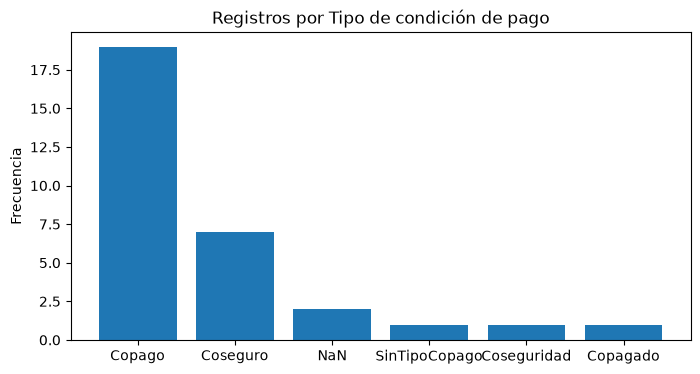

In [70]:
pd_tipo = FuenteCondicionesPago.groupBy('Tipo').count().orderBy(f.desc('count')).toPandas()
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(pd_tipo['Tipo'], pd_tipo['count'])
ax.set_title('Registros por Tipo de condición de pago')
ax.set_ylabel('Frecuencia')
plt.show()

**Validez:** `Tipo` toma 6 valores cuando solo deberían existir `Copago` y `Coseguro`. Hay **5 filas fuera del dominio**: `Coseguridad` (Id 9), `Copagado` (Id 34), `SinTipoCopago` (Id 68) y `NaN` (Id 221, dos veces). Las descripciones no presentan problemas de formato.

### Consistencia

In [71]:
res_cond = []
base_cond = FuenteCondicionesPago.dropDuplicates().cache()
n_cond = base_cond.count()

# DENTRO DE LA FILA
copay = col('Descripcion').startswith('Copay')
coins = col('Descripcion').startswith('Coinsurance')
registrar(res_cond, "Descripcion 'Copay...' con Tipo distinto de 'Copago'",
          base_cond.filter(copay & (col('Tipo') != 'Copago')), base_cond.filter(copay).count())
registrar(res_cond, "Descripcion 'Coinsurance...' con Tipo distinto de 'Coseguro'",
          base_cond.filter(coins & (col('Tipo') != 'Coseguro')), base_cond.filter(coins).count())

# ENTRE FILAS
g = base_cond.groupBy('IdCondicionesDePago_T').agg(f.countDistinct('Descripcion').alias('k'))
registrar(res_cond, 'IdCondicionesDePago_T con más de una Descripcion', g.filter('k > 1'), g.count())
g = base_cond.groupBy('Descripcion').agg(f.countDistinct('IdCondicionesDePago_T').alias('k'))
registrar(res_cond, 'Descripcion asociada a más de un IdCondicionesDePago_T', g.filter('k > 1'), g.count())

# ENTRE FUENTES
tipos_cond = base_cond.select(col('IdCondicionesDePago_T').alias('id'), 'Tipo').distinct()
copago_planes = FuentePlanesBeneficio.select(col('IdCondicionDePagoCopago_T').alias('id'))
coseguro_planes = FuentePlanesBeneficio.select(col('IdCondicionDePagoCoseguro_T').alias('id'))
registrar(res_cond, 'IdCondicionDePagoCopago_T de PlanesBeneficio sin correspondencia',
          copago_planes.distinct().join(tipos_cond, 'id', 'left_anti'), copago_planes.distinct().count())
registrar(res_cond, 'IdCondicionDePagoCoseguro_T de PlanesBeneficio sin correspondencia',
          coseguro_planes.distinct().join(tipos_cond, 'id', 'left_anti'), coseguro_planes.distinct().count())
registrar(res_cond, "Filas de PlanesBeneficio cuya condición de copago no es Tipo 'Copago'",
          copago_planes.join(tipos_cond, 'id').filter(col('Tipo') != 'Copago'), copago_planes.count())
registrar(res_cond, "Filas de PlanesBeneficio cuya condición de coseguro no es Tipo 'Coseguro'",
          coseguro_planes.join(tipos_cond, 'id').filter(col('Tipo') != 'Coseguro'), coseguro_planes.count())

mostrar_resultados(res_cond)

+-------------------------------------------------------------------------+-----+-----------+-----+
|chequeo                                                                  |casos|sobre_total|%    |
+-------------------------------------------------------------------------+-----+-----------+-----+
|Descripcion 'Copay...' con Tipo distinto de 'Copago'                     |2    |15         |13.33|
|Descripcion 'Coinsurance...' con Tipo distinto de 'Coseguro'             |0    |3          |0.0  |
|IdCondicionesDePago_T con más de una Descripcion                         |1    |23         |4.35 |
|Descripcion asociada a más de un IdCondicionesDePago_T                   |7    |17         |41.18|
|IdCondicionDePagoCopago_T de PlanesBeneficio sin correspondencia         |0    |14         |0.0  |
|IdCondicionDePagoCoseguro_T de PlanesBeneficio sin correspondencia       |0    |5          |0.0  |
|Filas de PlanesBeneficio cuya condición de copago no es Tipo 'Copago'    |16409|36036      |45.54|


In [72]:
base_cond.filter(col('Descripcion').isin('Copay per Stay', 'Coinsurance', 'No Charge', 'Not Applicable', 'No Charge after deductible')) \
    .orderBy('Descripcion', 'IdCondicionesDePago_T').show(truncate=False)

+---------------------+--------------------------+-----------+
|IdCondicionesDePago_T|Descripcion               |Tipo       |
+---------------------+--------------------------+-----------+
|45                   |Coinsurance               |Coseguro   |
|135                  |Coinsurance               |Coseguro   |
|221                  |Copay per Stay            |NaN        |
|663                  |Copay per Stay            |Copago     |
|9                    |No Charge                 |Coseguridad|
|51                   |No Charge                 |Copago     |
|18                   |No Charge after deductible|Coseguro   |
|207                  |No Charge after deductible|Copago     |
|34                   |Not Applicable            |Copagado   |
|36                   |Not Applicable            |Coseguro   |
+---------------------+--------------------------+-----------+



**Consistencia:**
- **Dentro de la fila:** 2 de los 15 registros únicos con descripción *Copay...* no tienen `Tipo` = `Copago` (Id 68 `SinTipoCopago` e Id 221 `NaN`). Todas las descripciones *Coinsurance...* tienen `Tipo` = `Coseguro`.
- **Entre filas:** el Id 204 tiene dos descripciones. Además, 7 de 17 descripciones están en más de un Id. En *No Charge* y *Not Applicable* tiene sentido, porque existe una versión para copago y otra para coseguro (por ejemplo, 51 Copago y 9 Coseguridad). En cambio, *Coinsurance* (45 y 135) y *Copay per Stay* (221 y 663) se repiten con el mismo tipo.
- **Entre fuentes:** todas las condiciones que usa FuentePlanesBeneficio existen en el catálogo. Sin embargo, **16.409 filas de planes (45,54%)** usan como copago una condición cuyo tipo no es `Copago` (Id 34 `Copagado`, Id 68 `SinTipoCopago`, Id 221 `NaN`), y **471 filas (1,31%)** usan como coseguro el Id 9 (`Coseguridad`). Esto confirma que esos tipos son errores de escritura de `Copago` y `Coseguro`.

### Herramienta de perfilamiento

In [73]:
plt.switch_backend('agg')
reporte_cond = ProfileReport(FuenteCondicionesPago.toPandas(), title='FuenteCondicionesDePago')
reporte_cond.to_file(OUT / 'reporte_FuenteCondicionesPago.html')
plt.switch_backend(backend_notebook)
print(f"Reporte guardado en {OUT / 'reporte_FuenteCondicionesPago.html'}")
for alerta in reporte_cond.get_description().alerts:
    print('-', alerta)

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 3/3 [00:00<00:00, 264.18it/s]
c:\Users\astri\Desktop\Maestria\CICLO 2 - 1 semestre\Entregables_ETL\.venv\Lib\site-packages\data_profiling\model\pandas\discretize_pandas.py:52: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[2 2 0 1 0 1 0 3 2 2 0 0 1 2 0 1 0 0 3 0 9 1 9 2 0 3 2 0 2 1 0]' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.
  discretized_df.loc[:, column] = self._discretize_column(


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Reporte guardado en C:\Users\astri\MIID4103\salidas\reporte_FuenteCondicionesPago.html
- Dataset has 7 (22.6%) duplicate rows


**Interpretación del reporte de la herramienta:** la única alerta son los **7 duplicados (22,6%)**. Con solo 31 filas, la herramienta no detecta los valores inválidos de `Tipo` (`NaN` lo toma como un texto más), ni el Id 204 con dos descripciones, ni las inconsistencias con PlanesBeneficio. Como dice el tutorial, el reporte sin interpretación y sin análisis propio no es suficiente.

### Conclusión – FuenteCondicionesDePago

Es una tabla pequeña (31 filas), pero **sus errores tienen un impacto alto, porque se propagan a FuentePlanesBeneficio**:

- **Unicidad:** 7 filas (22,6%) son duplicados exactos, y el Id 204 tiene dos descripciones distintas. Por eso el Id no identifica de forma única una condición de pago.
- **Completitud:** no hay nulos ni vacíos, pero `Tipo` tiene 2 valores con el texto `NaN` (Id 221). Son faltantes disfrazados que una revisión de nulos no detecta.
- **Validez:** `Tipo` debería tomar solo `Copago` o `Coseguro`, pero tiene 6 valores distintos: hay 5 filas con `Coseguridad`, `Copagado`, `SinTipoCopago` y `NaN`.
- **Consistencia:** dentro de la tabla, 2 condiciones con descripción *Copay* no tienen tipo `Copago`. Entre fuentes, todos los Id que usa PlanesBeneficio existen en el catálogo, pero por los tipos mal escritos **16.409 filas de planes (45,54%)** quedan asociadas como copago a una condición que no es `Copago`, y **471 (1,31%)** como coseguro a una que no es `Coseguro`.
- **Herramienta:** el reporte solo alertó sobre los duplicados. No identificó los tipos inválidos, el texto `NaN` ni el Id con dos descripciones.

La corrección es sencilla: eliminar los duplicados, homologar `Tipo` a {Copago, Coseguro} según la descripción y el uso que tienen en PlanesBeneficio, y que el negocio defina la descripción correcta del Id 204. Por su efecto sobre casi la mitad de los planes, esta limpieza debería hacerse primero.

## 3.3 FuentePlanesBeneficio

**¿Qué es una fila de la fuente?**
- **FuentePlanesBeneficio:** un tipo de beneficio (`IdTipoBeneficio_T`) ofrecido dentro de un plan (`IdPlan_T`) de un proveedor (`IdProveedor_T`), para un nivel de servicio (`IdNivelServicio_T`) y un año (`Fecha`), con sus condiciones de pago (copago y coseguro) y, cuando aplica, una cantidad límite.

In [74]:
FuentePlanesBeneficio.select('valorCopago', 'valorCoseguro', 'cantidadLimite', 'IdNivelServicio_T').summary().show()

+-------+------------------+------------------+-----------------+------------------+
|summary|       valorCopago|     valorCoseguro|   cantidadLimite| IdNivelServicio_T|
+-------+------------------+------------------+-----------------+------------------+
|  count|             36036|             36036|             5465|             36036|
|   mean| 9.778416028416029| 24.29279054279054|129.3313815187557|1.9995282495282496|
| stddev|100.41137967701272|36.959755494458506|951.2795862330698|0.8173400355652516|
|    min|                 0|                 0|                1|                 1|
|    25%|                 0|                 0|                1|                 1|
|    50%|                 0|                 0|               25|                 2|
|    75%|                 0|                50|               40|                 3|
|    max|              3500|               100|            30000|                 3|
+-------+------------------+------------------+-----------------+

### Completitud
Se crea la función `contar_vacios`, además de los nulos, las **cadenas vacías** en las columnas de texto: un texto vacío no es nulo para Spark, pero tampoco aporta información.

In [75]:
def contar_vacios(df):
    total = df.count()
    resultados = {}
    for c, tipo in df.dtypes:
        condicion = col(c).isNull()
        if tipo == 'string':
            condicion = condicion | (f.trim(col(c)) == '')
        vacios = df.filter(condicion).count()
        if vacios != 0:
            print(f'número de vacíos para columna {c}: {vacios} ({vacios / total:.1%})')
            resultados[c] = vacios
    return resultados

print('FuentePlanesBeneficio:')
vacios_planes = contar_vacios(FuentePlanesBeneficio)

FuentePlanesBeneficio:
número de vacíos para columna IdTipoBeneficio_T: 2086 (5.8%)
número de vacíos para columna IdAreaDeServicio_T: 2041 (5.7%)
número de vacíos para columna IdPlan_T: 2053 (5.7%)
número de vacíos para columna cantidadLimite: 30571 (84.8%)


In [76]:
# ¿Los faltantes ocurren en las mismas filas?
FuentePlanesBeneficio.select(
    f.sum(when(col('IdTipoBeneficio_T').isNull() & col('IdAreaDeServicio_T').isNull(), 1).otherwise(0)).alias('tipo_y_area_nulos'),
    f.sum(when(col('IdTipoBeneficio_T').isNull() & (f.trim(col('IdPlan_T')) == ''), 1).otherwise(0)).alias('tipo_nulo_y_plan_vacio'),
    f.sum(when(col('IdTipoBeneficio_T').isNull() | col('IdAreaDeServicio_T').isNull() | (f.trim(col('IdPlan_T')) == ''), 1).otherwise(0)).alias('filas_con_algun_faltante')
).show()

+-----------------+----------------------+------------------------+
|tipo_y_area_nulos|tipo_nulo_y_plan_vacio|filas_con_algun_faltante|
+-----------------+----------------------+------------------------+
|                0|                     0|                    6180|
+-----------------+----------------------+------------------------+



**Conclusiones de completitud**

*FuentePlanesBeneficio*
- `IdTipoBeneficio_T` tiene 2.086 nulos (5,8 %) e `IdAreaDeServicio_T` tiene 2.041 (5,7 %). Sin el tipo de beneficio la fila no se puede relacionar con el catálogo, y sin área no se sabe dónde aplica el plan.
- `IdPlan_T` no tiene nulos, pero sí 2.053 **cadenas vacías** (5,7 %). Este faltante "escondido" no lo detecta `isNull()` ni la herramienta de perfilamiento.
- `cantidadLimite` está vacía en 30.571 filas (84,8 %). Esto puede ser esperado si la mayoría de beneficios no tienen límite cuantitativo, pero hay que confirmarlo con el negocio.
- Los faltantes de tipo, área y plan nunca coinciden en la misma fila: en total 6.180 filas (17,1 %) tienen alguno. Eliminar todas las filas incompletas implicaría perder ese porcentaje de los datos.
- `Fecha` tampoco tiene nulos, pero 2.052 filas traen `1920-12-31`, que parece un valor por defecto en lugar de un dato real (ver Validez).

### Unicidad
Primero se buscan duplicados totales (filas idénticas) y después duplicados por la llave de cada tabla, es decir, la combinación de atributos que debería identificar una fila.

In [77]:
for nombre, df in [('FuentePlanesBeneficio', FuentePlanesBeneficio), ('FuenteTiposBeneficio', FuenteTiposBeneficio)]:
    total, distintos = df.count(), df.distinct().count()
    print(f'{nombre}: {total} filas, {distintos} distintas, {total - distintos} duplicados totales ({(total - distintos) / total:.1%})')

FuentePlanesBeneficio: 36036 filas, 27543 distintas, 8493 duplicados totales (23.6%)
FuenteTiposBeneficio: 849 filas, 578 distintas, 271 duplicados totales (31.9%)


En **FuentePlanesBeneficio** una fila debería ser única por plan, tipo de beneficio, año y nivel de servicio (`IdPlan_T`, `IdTipoBeneficio_T`, `Fecha`, `IdNivelServicio_T`). Se revisa sobre las filas sin duplicados totales y con plan informado:

In [78]:
planes_unicos = FuentePlanesBeneficio.distinct()
llave_planes = ['IdPlan_T', 'IdTipoBeneficio_T', 'Fecha', 'IdNivelServicio_T']
repetidas = planes_unicos.filter(f.trim(col('IdPlan_T')) != '').groupBy(llave_planes).count().filter(col('count') > 1)
filas_involucradas = repetidas.agg(f.sum('count')).first()[0]
print('Combinaciones de llave repetidas:', repetidas.count())
print('Filas involucradas:', filas_involucradas, '| filas sobrantes:', filas_involucradas - repetidas.count())
repetidas.orderBy(col('count').desc()).show(5)

Combinaciones de llave repetidas: 542
Filas involucradas: 2043 | filas sobrantes: 1501
+-----------------+-----------------+----------+-----------------+-----+
|         IdPlan_T|IdTipoBeneficio_T|     Fecha|IdNivelServicio_T|count|
+-----------------+-----------------+----------+-----------------+-----+
|40047MI0070001-00|             NULL|2017-12-31|                2|   16|
|40047MI0070001-00|             NULL|2017-12-31|                1|   15|
|40047MI0070001-00|             NULL|2017-12-31|                3|   14|
|74917MI0010003-01|              825|2017-12-31|                1|   12|
|74917MI0010003-01|              825|2017-12-31|                3|   10|
+-----------------+-----------------+----------+-----------------+-----+
only showing top 5 rows


In [79]:
planes_unicos.filter((col('IdPlan_T') == '40047MI0070001-00') & (col('IdTipoBeneficio_T') == 5) & (col('Fecha') == '2017-12-31')) \
    .orderBy('IdNivelServicio_T').show()

+-----------------+------------------+-------------------------+---------------------------+-----------------+-----------------+----------+-------------+-----------+-------------+--------------+
|IdTipoBeneficio_T|IdAreaDeServicio_T|IdCondicionDePagoCopago_T|IdCondicionDePagoCoseguro_T|IdNivelServicio_T|         IdPlan_T|     Fecha|IdProveedor_T|valorCopago|valorCoseguro|cantidadLimite|
+-----------------+------------------+-------------------------+---------------------------+-----------------+-----------------+----------+-------------+-----------+-------------+--------------+
|                5|          51632017|                      238|                         45|                1|40047MI0070001-00|2017-12-31|        40047|          0|            0|          NULL|
|                5|          52222017|                      238|                         45|                1|40047MI0070001-00|2017-12-31|        40047|          0|            0|          NULL|
|                5|      

**Conclusiones de unicidad**
- **FuentePlanesBeneficio** tiene 8.493 filas completamente repetidas (23,6 %), que deben eliminarse. Después de quitarlas, todavía hay 542 combinaciones de plan, tipo, año y nivel de servicio repetidas (2.043 filas, 1.501 sobrantes). En el ejemplo del plan `40047MI0070001-00` las filas repetidas solo cambian en `IdAreaDeServicio_T`. Esto sugiere que la llave real incluye el área de servicio, pero hay que confirmarlo con el negocio.

### Validez
Se revisa el formato de las fechas y de los identificadores de texto, el dominio de las variables categóricas y el rango de las variables numéricas.

#### Formato de `Fecha` en FuentePlanesBeneficio
Se usa una expresión regular para el formato `YYYY-MM-DD`, como en el tutorial.

In [80]:
regex_fecha = r'^[0-2]\d{3}-(0[1-9]|1[0-2])-(0[1-9]|[1-2][0-9]|3[0-1])$'
no_cumplen = FuentePlanesBeneficio.filter(~col('Fecha').rlike(regex_fecha))
print('Filas con Fecha fuera del formato YYYY-MM-DD:', no_cumplen.count())
FuentePlanesBeneficio.groupBy('Fecha').count().orderBy('Fecha').show()

Filas con Fecha fuera del formato YYYY-MM-DD: 2056
+-----------+-----+
|      Fecha|count|
+-----------+-----+
| 1920-12-31| 2052|
| 2017-12-31|16134|
| 2018-12-31|15794|
|Dec 31,2017| 1029|
|Dec 31,2018| 1027|
+-----------+-----+



#### Formato de `IdPlan_T`
Los identificadores de plan siguen el patrón: 5 dígitos del proveedor, 2 letras del estado, 7 dígitos, un guion y 2 dígitos de la variante (ej. `16842FL0070128-03`).

In [81]:
regex_plan = r'^\d{5}[A-Z]{2}\d{7}-\d{2}$'
FuentePlanesBeneficio.filter(~col('IdPlan_T').rlike(regex_plan)).groupBy('IdPlan_T').count().show()

+--------+-----+
|IdPlan_T|count|
+--------+-----+
|        | 2053|
+--------+-----+



#### Rango de las variables numéricas de FuentePlanesBeneficio
`valorCoseguro` es un porcentaje (0 a 100), `valorCopago` es un valor en dinero y `cantidadLimite` es una cantidad positiva. Además se revisan los dominios de los identificadores de condición de pago y de nivel de servicio.

In [82]:
FuentePlanesBeneficio.select(
    f.sum(when((col('valorCoseguro') < 0) | (col('valorCoseguro') > 100), 1).otherwise(0)).alias('coseguro_fuera_0_100'),
    f.sum(when(col('valorCopago') < 0, 1).otherwise(0)).alias('copago_negativo'),
    f.sum(when(col('valorCopago') > 100, 1).otherwise(0)).alias('copago_mayor_100'),
    f.sum(when(col('cantidadLimite') <= 0, 1).otherwise(0)).alias('limite_no_positivo'),
    f.sum(when(col('cantidadLimite') > 100, 1).otherwise(0)).alias('limite_mayor_100')
).show()

for c in ['IdNivelServicio_T', 'IdCondicionDePagoCopago_T', 'IdCondicionDePagoCoseguro_T']:
    FuentePlanesBeneficio.groupBy(c).count().orderBy(col('count').desc()).show(20)

+--------------------+---------------+----------------+------------------+----------------+
|coseguro_fuera_0_100|copago_negativo|copago_mayor_100|limite_no_positivo|limite_mayor_100|
+--------------------+---------------+----------------+------------------+----------------+
|                   0|              0|             441|                 0|             319|
+--------------------+---------------+----------------+------------------+----------------+

+-----------------+-----+
|IdNivelServicio_T|count|
+-----------------+-----+
|                1|12045|
|                3|12028|
|                2|11963|
+-----------------+-----+

+-------------------------+-----+
|IdCondicionDePagoCopago_T|count|
+-------------------------+-----+
|                      238|18123|
|                       34|16364|
|                       51|  612|
|                      207|  325|
|                      153|  290|
|                      170|  124|
|                      102|   50|
|               

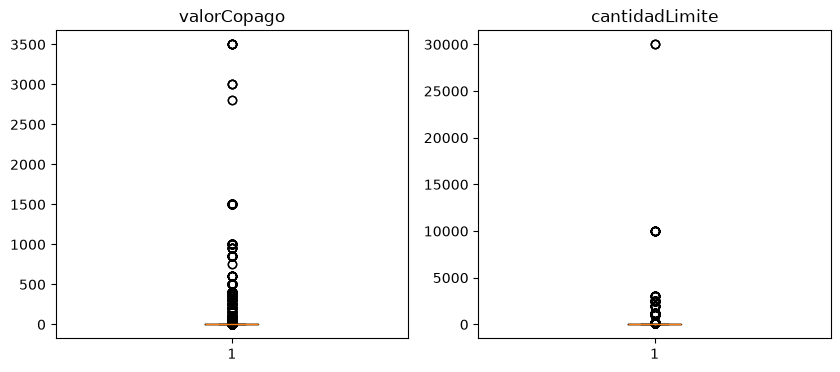

+--------------+-----+
|cantidadLimite|count|
+--------------+-----+
|         30000|    3|
|         10000|   16|
|          3000|   23|
|          2500|   60|
|          2000|   24|
+--------------+-----+
only showing top 5 rows


In [83]:
%matplotlib inline
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.set_title('valorCopago')
ax1.boxplot([row[0] for row in FuentePlanesBeneficio.select('valorCopago').dropna().collect()])
ax2.set_title('cantidadLimite')
ax2.boxplot([row[0] for row in FuentePlanesBeneficio.select('cantidadLimite').dropna().collect()])
plt.show()

FuentePlanesBeneficio.groupBy('cantidadLimite').count().orderBy(col('cantidadLimite').desc()).show(5)

**Conclusiones de validez**
- **Fecha (planes):** 2.056 filas traen otro formato (`Dec 31,2017` y `Dec 31,2018`). Es solo un problema de formato y se puede estandarizar a `YYYY-MM-DD`. Además, 2.052 filas tienen `1920-12-31`: el formato es correcto pero el valor no tiene sentido, se recomienda validar con la empresa si este es un error en la escritura o identificar porque sale este registro, porque los demás datos son de 2017 y 2018. Es un valor por defecto que esconde un faltante. En Consistencia se muestra que el año real se puede recuperar.
- **IdPlan_T:** todos los planes informados cumplen el patrón. Solo fallan los 2.053 vacíos.
- **Rangos:** `valorCoseguro` está siempre entre 0 y 100 y no hay valores negativos. `valorCopago` es 0 en la mayoría de filas, pero 441 filas superan 100 (hasta 3.500). `cantidadLimite` supera 100 en 319 filas y llega hasta 30.000. Estos valores extremos pueden ser válidos si el límite está en dólares (ver `UnidadDelLimite` = `Dollars per ...`), así que se reportan como atípicos para confirmar, no como errores.
- Los dominios de `IdNivelServicio_T` (1, 2, 3) y de las condiciones de pago son pequeños y no muestran valores extraños. Habría que validarlos contra `FuenteCondicionesDePago`.

### Consistencia
Se revisa la coherencia **dentro de una fila** (atributos que dependen entre sí) y **entre fuentes** (integridad referencial entre planes y tipos de beneficio).

#### Proveedor contra plan
Los 5 primeros dígitos de `IdPlan_T` corresponden al proveedor, así que deberían coincidir con `IdProveedor_T`.

In [84]:
planes_informados = FuentePlanesBeneficio.filter(f.trim(col('IdPlan_T')) != '')
print('Planes informados:', planes_informados.count())
print('Proveedor distinto al prefijo del plan:',
      planes_informados.filter(f.substring('IdPlan_T', 1, 5) != col('IdProveedor_T').cast('string')).count())

Planes informados: 33983
Proveedor distinto al prefijo del plan: 0


#### Área de servicio contra año
Los últimos 4 dígitos de `IdAreaDeServicio_T` parecen corresponder al año del plan (ej. área `10382017` con fecha `2017-12-31`). Se compara ese sufijo con el año de `Fecha`:

In [85]:
areas = FuentePlanesBeneficio.filter(col('IdAreaDeServicio_T').isNotNull()) \
    .withColumn('sufijo_area', f.substring(col('IdAreaDeServicio_T').cast('string'), -4, 4)) \
    .withColumn('anio_fecha', f.regexp_extract('Fecha', r'(\d{4})', 1))
areas.groupBy('anio_fecha', 'sufijo_area').count().orderBy('anio_fecha', 'sufijo_area').show()

+----------+-----------+-----+
|anio_fecha|sufijo_area|count|
+----------+-----------+-----+
|      1920|       2017|  986|
|      1920|       2018| 1066|
|      2017|       2017|15019|
|      2017|       4035| 1066|
|      2018|       2018|14849|
|      2018|       4036| 1009|
+----------+-----------+-----+



**Conclusiones de consistencia**
- **Proveedor contra plan:** todas las filas con plan informado son coherentes, porque el prefijo de `IdPlan_T` siempre coincide con `IdProveedor_T`. Esto también muestra que `IdProveedor_T` es redundante con el plan.
- **Área contra año:** en 29.868 filas el sufijo del área coincide con el año de `Fecha`. Hay tres excepciones:
  - Las 2.052 filas con `Fecha = 1920-12-31` tienen sufijo 2017 (986) o 2018 (1.066) en el área. Esto confirma que 1920 es un valor por defecto y que el año real se puede recuperar del área.
  - 1.066 filas de 2017 tienen sufijo 4035 y 1.009 filas de 2018 tienen sufijo 4036 (4035 = 2017 + 2018 y 4036 = 2018 + 2018). Esto sugiere un error al construir la llave del área que se debe consultar.
  - Además, el área viene como entero, así que pierde los ceros a la izquierda y tiene longitudes de 5 a 9 dígitos.

### Herramienta de perfilamiento

In [86]:
backend_notebook = plt.get_backend()
plt.switch_backend('agg')   # evita que el kernel se quede sin memoria
reporte = ProfileReport(FuentePlanesBeneficio.toPandas(), title='Perfilamiento planes_beneficio')
reporte.to_file(OUT / 'reporte_planes_beneficio.html')
print(f"Reporte guardado en {OUT / 'reporte_planes_beneficio.html'}")
plt.switch_backend(backend_notebook)

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 11/11 [00:00<00:00, 288.77it/s]
c:\Users\astri\Desktop\Maestria\CICLO 2 - 1 semestre\Entregables_ETL\.venv\Lib\site-packages\data_profiling\model\pandas\discretize_pandas.py:52: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 9 9 ... 9 9 0]' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.
  discretized_df.loc[:, column] = self._discretize_column(
c:\Users\astri\Desktop\Maestria\CICLO 2 - 1 semestre\Entregables_ETL\.venv\Lib\site-packages\data_profiling\model\pandas\discretize_pandas.py:52: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[4 9 9 ... 2 9 9]' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.
  discretized_df.loc[:, column] = self._discretize_column(
c:\Users\astri\Desktop\Maestria\CICLO 2 - 1 semestre\Entregables_ETL\.venv\Lib\site-packages\

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Reporte guardado en C:\Users\astri\MIID4103\salidas\reporte_planes_beneficio.html


## 2.4 FuenteTiposBeneficio

**¿Qué es una fila de la fuente?**
- **FuenteTiposBeneficio:** el catálogo de tipos de beneficio por año (`Fecha` es solo el año). Describe el nombre del beneficio, la unidad del límite y varias banderas Yes/No (si es EHB, si está cubierto por el seguro, si tiene límite cuantitativo y si se excluye del desembolso máximo dentro o fuera de la red).

### Completitud

In [87]:
print('FuenteTiposBeneficio:')
vacios_tipos = contar_vacios(FuenteTiposBeneficio)

FuenteTiposBeneficio:
número de vacíos para columna UnidadDelLimite: 559 (65.8%)


**Conclusiones de completitud**

*FuenteTiposBeneficio*
- No hay nulos. `UnidadDelLimite` está vacía en 559 filas (65,8 %), lo cual es esperado cuando el beneficio no tiene límite cuantitativo. Esa relación se valida en Consistencia.

### Unicidad

En **FuenteTiposBeneficio** la llave esperada es el tipo de beneficio por año (`IdTipoBeneficio_T`, `Fecha`). Se revisa sobre las filas sin duplicados totales:

In [88]:
tipos_unicos = FuenteTiposBeneficio.distinct()
print('Filas sin duplicados totales:', tipos_unicos.count())
print('Ids de tipo distintos:', tipos_unicos.select('IdTipoBeneficio_T').distinct().count())
print('Combinaciones (Id, Fecha) distintas:', tipos_unicos.select('IdTipoBeneficio_T', 'Fecha').distinct().count())

versiones = tipos_unicos.groupBy('IdTipoBeneficio_T', 'Fecha').count().filter(col('count') > 1)
print('Combinaciones (Id, Fecha) con más de una versión:', versiones.count())
versiones.orderBy(col('count').desc()).show(5)

# Relación Id <-> Nombre
print('Nombres con más de un Id:', tipos_unicos.groupBy('Nombre').agg(f.countDistinct('IdTipoBeneficio_T').alias('ids')).filter(col('ids') > 1).count())
print('Ids con más de un Nombre:', tipos_unicos.groupBy('IdTipoBeneficio_T').agg(f.countDistinct('Nombre').alias('nombres')).filter(col('nombres') > 1).count())

Filas sin duplicados totales: 578
Ids de tipo distintos: 178
Combinaciones (Id, Fecha) distintas: 218
Combinaciones (Id, Fecha) con más de una versión: 117
+-----------------+-----+-----+
|IdTipoBeneficio_T|Fecha|count|
+-----------------+-----+-----+
|              865| 2017|   16|
|              190| 2017|   14|
|              830| 2017|   13|
|              335| 2017|   12|
|              275| 2017|   11|
+-----------------+-----+-----+
only showing top 5 rows
Nombres con más de un Id: 0
Ids con más de un Nombre: 0


In [89]:
# Ejemplo: el mismo tipo de beneficio en el mismo año con atributos contradictorios
tipos_unicos.filter(col('IdTipoBeneficio_T') == 5).orderBy('Fecha').show(truncate=False)

+-----------------+-----------------------------------------------+---------------+-----+---------------------+-----------------------+----------------------------------------+---------------------------------------+-----+
|IdTipoBeneficio_T|Nombre                                         |UnidadDelLimite|EsEHB|EstaCubiertaPorSeguro|TieneLimiteCuantitativo|ExcluidoDelDesembolsoMaximoDentroDeLaRed|ExcluidoDelDesembolsoMaximoFueraDeLaRed|Fecha|
+-----------------+-----------------------------------------------+---------------+-----+---------------------+-----------------------+----------------------------------------+---------------------------------------+-----+
|5                |Abortion for Which Public Funding is Prohibited|               |No   |No                   |No                     |No                                      |No                                     |2017 |
|5                |Abortion for Which Public Funding is Prohibited|               |Yes  |Yes                

**Conclusiones de unicidad**
- **FuenteTiposBeneficio** tiene 271 filas completamente repetidas (31,9 %). Sin ellas quedan 578 filas, pero solo 178 tipos de beneficio y 218 combinaciones (Id, año). Es decir, 117 combinaciones (Id, año) tienen varias versiones con banderas contradictorias (el tipo 865 llega a tener 16 versiones en 2017). Por ejemplo, el tipo 5 aparece en 2017 con `EsEHB` = Yes y = No a la vez. No se sabe cuál es la versión correcta, así que se debe consultar con el negocio.
- La relación entre `IdTipoBeneficio_T` y `Nombre` sí es 1 a 1 (ningún nombre tiene dos Ids ni al revés).

### Validez

#### Dominio de las variables categóricas de FuenteTiposBeneficio
Las banderas deberían tomar solo los valores `Yes` o `No`.

In [90]:
banderas = ['EsEHB', 'EstaCubiertaPorSeguro', 'TieneLimiteCuantitativo',
            'ExcluidoDelDesembolsoMaximoDentroDeLaRed', 'ExcluidoDelDesembolsoMaximoFueraDeLaRed']
for c in banderas:
    FuenteTiposBeneficio.groupBy(c).count().orderBy(col('count').desc()).show()

+-----+-----+
|EsEHB|count|
+-----+-----+
|  Yes|  430|
|   No|  399|
| True|   20|
+-----+-----+

+---------------------+-----+
|EstaCubiertaPorSeguro|count|
+---------------------+-----+
|                  Yes|  743|
|                   No|   98|
|                False|    8|
+---------------------+-----+

+-----------------------+-----+
|TieneLimiteCuantitativo|count|
+-----------------------+-----+
|                     No|  542|
|                    Yes|  271|
|                   Nein|   24|
|                     Si|   12|
+-----------------------+-----+

+----------------------------------------+-----+
|ExcluidoDelDesembolsoMaximoDentroDeLaRed|count|
+----------------------------------------+-----+
|                                      No|  787|
|                                     Yes|   60|
|                           Algunas veces|    2|
+----------------------------------------+-----+

+---------------------------------------+-----+
|ExcluidoDelDesembolsoMaximoFueraDeLaRed|

In [91]:
# UnidadDelLimite: textos repetidos varias veces y diferencias de mayúsculas/minúsculas
unidades = FuenteTiposBeneficio.filter(f.trim(col('UnidadDelLimite')) != '')
repetidas_unidad = unidades.filter(col('UnidadDelLimite').rlike(r'^(.+)\1\1$'))
print('Filas con la unidad escrita tres veces seguidas:', repetidas_unidad.count())
repetidas_unidad.groupBy('UnidadDelLimite').count().orderBy(col('count').desc()).show(5, truncate=False)

print('Unidades distintas tal como vienen:', unidades.select('UnidadDelLimite').distinct().count())
print('Unidades distintas sin mayúsculas:', unidades.select(f.lower('UnidadDelLimite')).distinct().count())
unidades.filter(col('UnidadDelLimite').rlike(r'per (year|\d+ months|lifetime)$')).groupBy('UnidadDelLimite').count().show(truncate=False)

Filas con la unidad escrita tres veces seguidas: 40
+---------------------------------------------------------------------------------+-----+
|UnidadDelLimite                                                                  |count|
+---------------------------------------------------------------------------------+-----+
|Visit(s) per YearVisit(s) per YearVisit(s) per Year                              |11   |
|Visit(s) per Benefit PeriodVisit(s) per Benefit PeriodVisit(s) per Benefit Period|7    |
|Months per LifetimeMonths per LifetimeMonths per Lifetime                        |3    |
|Months per ProcedureMonths per ProcedureMonths per Procedure                     |3    |
|Dollars per YearDollars per YearDollars per Year                                 |2    |
+---------------------------------------------------------------------------------+-----+
only showing top 5 rows
Unidades distintas tal como vienen: 62
Unidades distintas sin mayúsculas: 58
+-------------------------+-----+
|Un

**Conclusiones de validez**
- **Banderas de tipos de beneficio:** hay valores fuera del dominio Yes/No. `EsEHB` trae `True` (20), `EstaCubiertaPorSeguro` trae `False` (8) y `TieneLimiteCuantitativo` trae `Si` (12) y `Nein` (24), que son el mismo significado en otro idioma o formato y se pueden homologar. `ExcluidoDelDesembolsoMaximoDentroDeLaRed` trae `Algunas veces` (2), que no se puede traducir a Yes/No y se debe consultar con el negocio.
- **UnidadDelLimite:** 40 filas tienen el texto repetido tres veces (ej. `Visit(s) per YearVisit(s) per YearVisit(s) per Year`) y hay variaciones de mayúsculas (`per year` frente a `per Year`). Por las mayúsculas, aparecen 62 unidades distintas en lugar de 58, y con la repetición triple el número real es todavía menor.

### Consistencia

#### Límite cuantitativo contra unidad del límite (FuenteTiposBeneficio)
Si un tipo de beneficio tiene límite cuantitativo, debería tener una unidad, y si no lo tiene, la unidad debería estar vacía. Para esta revisión se homologan `Si` como Yes y `Nein` como No.

In [92]:
limite = FuenteTiposBeneficio.distinct() \
    .withColumn('tiene_limite', when(col('TieneLimiteCuantitativo').isin('Yes', 'Si'), 'Yes').otherwise('No')) \
    .withColumn('tiene_unidad', when(f.trim(col('UnidadDelLimite')) != '', 'Yes').otherwise('No'))
limite.groupBy('tiene_limite', 'tiene_unidad').count().orderBy('tiene_limite', 'tiene_unidad').show()

+------------+------------+-----+
|tiene_limite|tiene_unidad|count|
+------------+------------+-----+
|          No|          No|  344|
|          No|         Yes|   14|
|         Yes|          No|    9|
|         Yes|         Yes|  211|
+------------+------------+-----+



**Conclusiones de consistencia**
- **Límite contra unidad:** 9 tipos de beneficio dicen tener límite cuantitativo pero no tienen unidad, y 14 dicen no tenerlo pero sí traen una unidad. Son contradicciones dentro de la misma fila.

### Herramienta de perfilamiento

In [93]:
backend_notebook = plt.get_backend()
plt.switch_backend('agg')   # evita que el kernel se quede sin memoria
reporte = ProfileReport(FuenteTiposBeneficio.toPandas(), title='Perfilamiento tipos_beneficio')
reporte.to_file(OUT / 'reporte_tipos_beneficio.html')
print(f"Reporte guardado en {OUT / 'reporte_tipos_beneficio.html'}")
plt.switch_backend(backend_notebook)

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 9/9 [00:00<00:00, 676.60it/s]
c:\Users\astri\Desktop\Maestria\CICLO 2 - 1 semestre\Entregables_ETL\.venv\Lib\site-packages\data_profiling\model\pandas\discretize_pandas.py:52: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[5 7 1 3 5 6 8 8 1 4 7 3 8 3 3 9 2 3 6 7 8 0 9 1 9 9 6 1 1 3 7 7 3 3 1 4 8
 1 1 2 3 7 1 1 2 3 5 6 7 9 3 6 7 6 3 3 9 1 1 1 3 0 0 4 0 3 6 0 2 7 7 4 1 0
 8 9 5 5 3 4 9 3 6 1 7 9 2 3 3 7 9 4 4 6 0 8 2 2 5 6 0 6 2 0 0 9 2 0 0 3 4
 8 8 2 3 0 1 3 3 5 1 7 9 7 1 2 3 9 7 7 3 2 7 2 4 7 7 8 5 4 6 7 7 8 0 2 7 8
 5 1 3 0 0 1 4 0 2 7 3 5 8 8 5 2 0 3 3 1 7 5 3 0 5 6 7 4 7 1 2 2 1 7 0 5 6
 7 7 5 8 8 0 5 4 7 7 5 0 9 3 7 7 3 4 1 5 6 6 5 6 8 1 0 7 6 3 4 8 8 1 1 5 8
 1 3 6 7 5 1 9 2 7 8 1 2 7 4 0 2 7 1 1 7 2 0 1 7 0 4 9 3 7 8 3 7 9 1 7 5 0
 6 7 9 1 6 0 3 9 6 7 5 6 7 7 4 5 3 3 6 7 8 1 2 0 7 9 3 3 3 6 3 4 7 7 0 0 3
 7 9 9 2 2 9 7 9 1 1 6 7 1 4 7 4 7 9 1 2 7 9 2 8 5 1 4 5 7 8 2 2 7 0 7 0 0
 5 3 7 9 2 3 3

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Reporte guardado en C:\Users\astri\MIID4103\salidas\reporte_tipos_beneficio.html


#### Interpretación de los reportes de FuentePlanesBeneficio y FuenteTiposBeneficio
Se usa **fg-data-profiling** (`ProfileReport`) para generar un reporte HTML por tabla con el resumen general, el análisis por variable, las alertas y las correlaciones. La herramienta es útil, *pero no perfecta ni completa*: los reportes se guardan en la carpeta `OUT`.

**¿Qué confirma el reporte y qué no detecta?**
- **Confirma:**
  - Hay muchas filas duplicadas en ambas tablas. La herramienta reporta 8.342 (23,1 %) en planes y 229 (27,0 %) en tipos, que no son exactamente los mismos números que se obtienen con `distinct()` en Spark (8.493 y 271). Para la limpieza se usan los conteos de Spark.
  - Los nulos de `IdTipoBeneficio_T` (5,8 %), `IdAreaDeServicio_T` (5,7 %) y `cantidadLimite` (84,8 %).
  - La asimetría de `cantidadLimite` y la gran cantidad de ceros en `valorCopago` (94,5 %) y `valorCoseguro` (60,9 %).
  - El desbalance de `ExcluidoDelDesembolsoMaximoDentroDeLaRed` y, en el detalle de cada variable, las categorías `True`, `False`, `Si`, `Nein` y `Algunas veces`.
- **No detecta:**
  - Las 2.053 cadenas vacías de `IdPlan_T` y las vacías de `UnidadDelLimite`, porque las cuenta como un valor más y no como faltantes. Por eso reporta 0 celdas faltantes en tipos de beneficio.
  - La fecha `1920-12-31` como valor por defecto, ni el formato `Dec 31,YYYY` como error.
  - La llave repetida con valores distintos.
  - Las inconsistencias entre columnas (área contra año, límite contra unidad) y entre fuentes (tipos de beneficio inexistentes).
- **Puede confundir:** trata los identificadores (`IdTipoBeneficio_T`, `IdAreaDeServicio_T`, `IdProveedor_T`, `IdCondicionDePagoCopago_T`) como variables numéricas. Les calcula media y genera alertas de "alta correlación" (por ejemplo entre `IdAreaDeServicio_T` e `IdProveedor_T`) que no tienen sentido analítico.

Por eso el reporte complementa, pero no reemplaza, las validaciones anteriores.

## 2.5 Análisis conjunto de las cuatro tablas
Las cuatro fuentes forman un modelo: **FuentePlanesBeneficio** es la tabla de hechos y se relaciona con tres catálogos: **FuenteAreasDeServicio** (`IdAreaDeServicio_T`), **FuenteTiposBeneficio** (`IdTipoBeneficio_T`) y **FuenteCondicionesDePago** (`IdCondicionDePagoCopago_T` e `IdCondicionDePagoCoseguro_T`). Se comparan las cuatro tablas y se revisa si los planes se pueden relacionar con sus tres catálogos al mismo tiempo.


### Consistencia entre fuentes

Se tienen 36.036 filas y 11 columnas de planes, y 849 filas y 9 columnas de tipos de beneficio. Note que `Fecha` es texto (`YYYY-MM-DD`) en planes y entero (año) en tipos: la misma variable tiene tipo y significado distintos en cada fuente.

#### Integridad referencial: planes contra tipos de beneficio
Todo `IdTipoBeneficio_T` de los planes debería existir en el catálogo de tipos de beneficio, y además para el mismo año.

In [94]:
ids_tipos = FuenteTiposBeneficio.select('IdTipoBeneficio_T').distinct()
planes_con_tipo = FuentePlanesBeneficio.filter(col('IdTipoBeneficio_T').isNotNull())

sin_tipo = planes_con_tipo.join(ids_tipos, 'IdTipoBeneficio_T', 'left_anti')
print('Filas de planes con un tipo de beneficio que no existe en el catálogo:', sin_tipo.count())
print('Tipos de beneficio inexistentes:', sin_tipo.select('IdTipoBeneficio_T').distinct().count())
sin_tipo.agg(f.min('IdTipoBeneficio_T').alias('min_id'), f.max('IdTipoBeneficio_T').alias('max_id')).show()
ids_tipos.agg(f.min('IdTipoBeneficio_T').alias('min_id_catalogo'), f.max('IdTipoBeneficio_T').alias('max_id_catalogo')).show()

print('Tipos del catálogo que ningún plan usa:', ids_tipos.join(planes_con_tipo.select('IdTipoBeneficio_T'), 'IdTipoBeneficio_T', 'left_anti').count())

Filas de planes con un tipo de beneficio que no existe en el catálogo: 2023
Tipos de beneficio inexistentes: 107
+------+------+
|min_id|max_id|
+------+------+
|  1060|  2110|
+------+------+

+---------------+---------------+
|min_id_catalogo|max_id_catalogo|
+---------------+---------------+
|              5|           1055|
+---------------+---------------+

Tipos del catálogo que ningún plan usa: 0


In [95]:
# Mismo tipo de beneficio y mismo año (se toma el año real de la fecha)
tipos_anio = FuenteTiposBeneficio.select('IdTipoBeneficio_T', col('Fecha').cast('string').alias('anio')).distinct()
planes_anio = planes_con_tipo.join(ids_tipos, 'IdTipoBeneficio_T', 'left_semi') \
    .withColumn('anio', f.regexp_extract('Fecha', r'(\d{4})', 1))
sin_tipo_en_anio = planes_anio.join(tipos_anio, ['IdTipoBeneficio_T', 'anio'], 'left_anti')
print('Filas cuyo tipo existe en el catálogo pero no para ese año:', sin_tipo_en_anio.count(), 'de', planes_anio.count())
sin_tipo_en_anio.groupBy('anio').count().orderBy('anio').show()

Filas cuyo tipo existe en el catálogo pero no para ese año: 8565 de 31927
+----+-----+
|anio|count|
+----+-----+
|1920| 2052|
|2018| 6513|
+----+-----+



**Conclusiones de consistencia**
- **Planes contra tipos de beneficio:** 107 tipos de beneficio usados en los planes (Ids de 1060 a 2110, 2.023 filas) no existen en el catálogo, cuyo Id máximo es 1055. En sentido contrario, todos los tipos del catálogo se usan en algún plan.
- **Planes contra tipos de beneficio por año:** 8.565 de 31.927 filas usan un tipo que existe en el catálogo pero no para el año del plan. 2.052 de ellas son las de fecha 1920 y las otras 6.513 son de 2018, porque el catálogo de 2018 solo tiene 62 tipos frente a 156 en 2017. Así no es posible obtener los atributos del beneficio para esas filas.
- **Entre fuentes:** `Fecha` es texto con fecha completa en planes y entero con el año en tipos. Para cruzarlas hay que llevar ambas al año.

### Panorama comparativo
Celdas faltantes = nulos, textos vacíos o el texto `NaN`, sobre el total de celdas de la tabla.

In [96]:
tablas_4 = [('FuenteAreasDeServicio', FuenteAreas), ('FuenteCondicionesDePago', FuenteCondicionesPago),
            ('FuentePlanesBeneficio', FuentePlanesBeneficio), ('FuenteTiposBeneficio', FuenteTiposBeneficio)]
resumen_4 = []
for nombre, df in tablas_4:
    total = df.count()
    duplicados = total - df.distinct().count()
    faltantes = 0
    for c, tipo in df.dtypes:
        condicion = col(c).isNull()
        if tipo == 'string':
            condicion = condicion | (f.trim(col(c)) == '') | (f.lower(f.trim(col(c))) == 'nan')
        faltantes += df.filter(condicion).count()
    resumen_4.append((nombre, total, len(df.columns), duplicados, round(100 * duplicados / total, 2),
                      round(100 * faltantes / (total * len(df.columns)), 2)))
spark.createDataFrame(resumen_4, ['tabla', 'filas', 'columnas', 'duplicados_exactos',
                                  'pct_duplicados', 'pct_celdas_faltantes']).show(truncate=False)

+-----------------------+------+--------+------------------+--------------+--------------------+
|tabla                  |filas |columnas|duplicados_exactos|pct_duplicados|pct_celdas_faltantes|
+-----------------------+------+--------+------------------+--------------+--------------------+
|FuenteAreasDeServicio  |188815|9       |43573             |23.08         |1.03                |
|FuenteCondicionesDePago|31    |3       |7                 |22.58         |2.15                |
|FuentePlanesBeneficio  |36036 |11      |8493              |23.57         |9.27                |
|FuenteTiposBeneficio   |849   |9       |271               |31.92         |7.32                |
+-----------------------+------+--------+------------------+--------------+--------------------+



Las cuatro tablas tienen entre **22,6% y 31,9% de filas duplicadas exactas**. Es un problema común a toda la fuente, así que eliminar duplicados debe ser el primer paso de la limpieza en todas las tablas. En celdas faltantes, **FuentePlanesBeneficio (9,27%)** y **FuenteTiposBeneficio (7,32%)** son las más afectadas. En planes pesan sobre todo `cantidadLimite` y los Ids nulos o vacíos, y en tipos los vacíos de `UnidadDelLimite`, que pueden ser esperados cuando no hay límite. FuenteAreasDeServicio (1,03%) y FuenteCondicionesDePago (2,15%) tienen pocos faltantes.

### Integridad referencial: planes contra los tres catálogos
Para cada fila de planes se verifica que el área exista en FuenteAreasDeServicio, que el tipo de beneficio exista en FuenteTiposBeneficio, y que la condición de copago sea de tipo `Copago` y la de coseguro de tipo `Coseguro` en FuenteCondicionesDePago. Un Id nulo cuenta como problema, porque esa fila tampoco se puede relacionar.

In [97]:
ids_areas_4 = FuenteAreas.filter(col('IdAreaDeServicio_T').isNotNull()) \
    .select(col('IdAreaDeServicio_T').cast('long').alias('IdAreaDeServicio_T')).distinct().withColumn('existe_area', f.lit(True))
ids_tipos_4 = FuenteTiposBeneficio.select(col('IdTipoBeneficio_T').cast('long').alias('IdTipoBeneficio_T')) \
    .distinct().withColumn('existe_tipo', f.lit(True))
tipos_cond_4 = FuenteCondicionesPago.groupBy('IdCondicionesDePago_T').agg(f.collect_set('Tipo').alias('tipos'))

planes_4 = (FuentePlanesBeneficio
    .join(ids_areas_4, 'IdAreaDeServicio_T', 'left')
    .join(ids_tipos_4, 'IdTipoBeneficio_T', 'left')
    .join(tipos_cond_4.select(col('IdCondicionesDePago_T').alias('IdCondicionDePagoCopago_T'), col('tipos').alias('tipos_copago')),
          'IdCondicionDePagoCopago_T', 'left')
    .join(tipos_cond_4.select(col('IdCondicionesDePago_T').alias('IdCondicionDePagoCoseguro_T'), col('tipos').alias('tipos_coseguro')),
          'IdCondicionDePagoCoseguro_T', 'left')
    .withColumn('area_ok', f.coalesce(col('existe_area'), f.lit(False)))
    .withColumn('tipo_ok', f.coalesce(col('existe_tipo'), f.lit(False)))
    .withColumn('copago_ok', f.coalesce(f.array_contains('tipos_copago', 'Copago'), f.lit(False)))
    .withColumn('coseguro_ok', f.coalesce(f.array_contains('tipos_coseguro', 'Coseguro'), f.lit(False)))
    .cache())

total_planes = planes_4.count()
res_4 = []
for chequeo, flag in [('Área nula o inexistente en FuenteAreasDeServicio', 'area_ok'),
                      ('Tipo de beneficio nulo o inexistente en FuenteTiposBeneficio', 'tipo_ok'),
                      ("Condición de copago que no es de tipo 'Copago'", 'copago_ok'),
                      ("Condición de coseguro que no es de tipo 'Coseguro'", 'coseguro_ok')]:
    registrar(res_4, chequeo, planes_4.filter(~col(flag)), total_planes)
todo_ok = col('area_ok') & col('tipo_ok') & col('copago_ok') & col('coseguro_ok')
registrar(res_4, 'Filas con al menos un problema de referencia', planes_4.filter(~todo_ok), total_planes)
mostrar_resultados(res_4)

print('Filas de planes que se relacionan correctamente con los tres catálogos:', planes_4.filter(todo_ok).count(), 'de', total_planes)
print('Las mismas, sin contar duplicados exactos:', planes_4.filter(todo_ok).select(FuentePlanesBeneficio.columns).distinct().count())

+------------------------------------------------------------+-----+-----------+-----+
|chequeo                                                     |casos|sobre_total|%    |
+------------------------------------------------------------+-----+-----------+-----+
|Área nula o inexistente en FuenteAreasDeServicio            |7020 |36036      |19.48|
|Tipo de beneficio nulo o inexistente en FuenteTiposBeneficio|4109 |36036      |11.4 |
|Condición de copago que no es de tipo 'Copago'              |16409|36036      |45.54|
|Condición de coseguro que no es de tipo 'Coseguro'          |471  |36036      |1.31 |
|Filas con al menos un problema de referencia                |22361|36036      |62.05|
+------------------------------------------------------------+-----+-----------+-----+

Filas de planes que se relacionan correctamente con los tres catálogos: 13675 de 36036
Las mismas, sin contar duplicados exactos: 10567


Este es el hallazgo más importante del análisis conjunto: **solo 13.675 de las 36.036 filas de planes (37,95%) se pueden relacionar correctamente con los tres catálogos al mismo tiempo**. Sin duplicados exactos quedan 10.567. El **62,05%** de las filas tiene al menos un problema de referencia:
- **Áreas (19,48%):** 7.020 filas tienen el área nula (2.041) o un área que no existe en FuenteAreasDeServicio (4.979).
- **Tipos de beneficio (11,4%):** 4.109 filas tienen el tipo nulo (2.086) o un tipo que no existe en el catálogo (2.023, Ids mayores a 1055).
- **Condición de copago (45,54%):** es el problema más grande y viene de los tipos mal escritos de FuenteCondicionesDePago (`Copagado`, `SinTipoCopago`, `NaN`). Por eso es también el más fácil de corregir: al homologar `Tipo` en un catálogo de 31 filas, se arreglan 16.409 filas de planes.
- **Condición de coseguro (1,31%):** 471 filas, por el tipo `Coseguridad` del Id 9.

In [98]:
# En sentido contrario: registros de los catálogos que ningún plan usa
areas_usadas = FuentePlanesBeneficio.select(col('IdAreaDeServicio_T').alias('id')).distinct()
cond_usadas = FuentePlanesBeneficio.select(col('IdCondicionDePagoCopago_T').alias('id')) \
    .union(FuentePlanesBeneficio.select(col('IdCondicionDePagoCoseguro_T').alias('id'))).distinct()
areas_cat = FuenteAreas.filter(col('IdAreaDeServicio_T').isNotNull()).select(col('IdAreaDeServicio_T').cast('long').alias('id')).distinct()
cond_cat = FuenteCondicionesPago.select(col('IdCondicionesDePago_T').alias('id')).distinct()
print('Áreas del catálogo que ningún plan usa:', areas_cat.join(areas_usadas, 'id', 'left_anti').count(), 'de', areas_cat.count())
print('Condiciones de pago que ningún plan usa:', cond_cat.join(cond_usadas, 'id', 'left_anti').count(), 'de', cond_cat.count())
cond_cat.join(cond_usadas, 'id', 'left_anti').join(
    FuenteCondicionesPago.select(col('IdCondicionesDePago_T').alias('id'), 'Descripcion', 'Tipo').distinct(), 'id').orderBy('id').show(truncate=False)

Áreas del catálogo que ningún plan usa: 10 de 5409
Condiciones de pago que ningún plan usa: 4 de 23
+---+-----------------------------+--------+
|id |Descripcion                  |Tipo    |
+---+-----------------------------+--------+
|119|Copay per Day with deductible|Copago  |
|135|Coinsurance                  |Coseguro|
|663|Copay per Stay               |Copago  |
|714|Copay                        |Copago  |
+---+-----------------------------+--------+



En sentido contrario, los catálogos casi no tienen registros sin uso. Solo 10 de las 5.409 áreas y 4 de las 23 condiciones de pago no aparecen en ningún plan. Las condiciones sin uso son los Id 119, 135, 663 y 714. Tres de ellas (135 *Coinsurance*, 663 *Copay per Stay* y 714 *Copay*) repiten la descripción de otra condición que sí se usa (45, 221 y 238), lo que refuerza la pregunta de si son registros duplicados con otro Id. El problema principal es entonces de **planes que apuntan a registros inexistentes**, no de catálogos con datos sobrantes.

### Cobertura de años entre las fuentes
El año viene en `Fecha` en las cuatro tablas excepto en FuenteCondicionesDePago, que no tiene fecha. En planes se toma el año del texto de la fecha.

In [99]:
anios_4 = (FuenteAreas.groupBy(col('Fecha').cast('string').alias('anio')).count().withColumn('tabla', f.lit('Areas'))
    .unionByName(FuentePlanesBeneficio.groupBy(f.regexp_extract('Fecha', r'(\d{4})', 1).alias('anio')).count().withColumn('tabla', f.lit('Planes')))
    .unionByName(FuenteTiposBeneficio.groupBy(col('Fecha').cast('string').alias('anio')).count().withColumn('tabla', f.lit('Tipos'))))
anios_4.groupBy('anio').pivot('tabla').sum('count').orderBy('anio').show()

+----+-----+------+-----+
|anio|Areas|Planes|Tipos|
+----+-----+------+-----+
|1800| 6282|  NULL| NULL|
|1920| NULL|  2052| NULL|
|2017|99211| 17163|  672|
|2018|83322| 16821|  177|
+----+-----+------+-----+



Las tres tablas con fecha comparten los años **2017 y 2018**, pero cada una tiene un año inválido distinto: **1800** en áreas (6.282 filas) y **1920** en planes (2.052 filas). En los dos casos el año real se puede recuperar del sufijo de `IdAreaDeServicio_T`. Además, la cobertura por año no está balanceada: planes tiene casi las mismas filas en 2017 (17.163) y 2018 (16.821), pero el catálogo de tipos de beneficio tiene 672 filas en 2017 y solo 177 en 2018. Por eso muchos planes de 2018 no encuentran su tipo de beneficio para ese año.

## 2.6 Resumen de hallazgos

### Resumen de hallazgos de las cuatro tablas

| Dimensión | FuenteAreasDeServicio | FuenteCondicionesDePago | FuentePlanesBeneficio | FuenteTiposBeneficio |
|---|---|---|---|---|
| **Completitud** | `IdAreaDeServicio_T` 3,33%, `IdGeografia_T` 3,38%, `Area`/`Densidad` 1,27% nulos | 2 `Tipo` con texto `NaN` | Nulos en `IdTipoBeneficio_T` (2.086) e `IdAreaDeServicio_T` (2.041); 2.053 `IdPlan_T` vacíos; `cantidadLimite` vacía en 84,8% | Sin nulos; `UnidadDelLimite` vacía en 559 filas |
| **Unicidad** | 43.573 duplicados (23,1%); 23.263 llaves con varias versiones | 7 duplicados (22,6%); Id 204 con dos descripciones | 8.493 duplicados (23,6%); 542 llaves repetidas | 271 duplicados (31,9%); 117 combinaciones (Id, año) contradictorias |
| **Validez** | 6.282 `Fecha` = 1800; 6.177 áreas negativas; 13.713 `IdGeografia_T` inválidos; poblaciones de ~10¹⁰ | 5 filas con `Tipo` fuera de {Copago, Coseguro} | 2.056 fechas `Dec 31,YYYY`; 2.052 fechas `1920-12-31` | Banderas con `True`, `False`, `Si`, `Nein`, `Algunas veces`; 40 unidades repetidas tres veces |
| **Consistencia** | 89,96% de condados con más de un `IdGeografia_T`; población y área distintas para el mismo condado | 2 descripciones *Copay* sin tipo `Copago` | Sufijo de área distinto al año (1920, 4035, 4036) | 23 contradicciones entre límite y unidad |
| **Entre fuentes** | 4.979 filas de planes con un área inexistente | 16.409 filas de planes con una condición de copago que no es `Copago` y 471 con una de coseguro que no es `Coseguro` | Solo 13.675 filas (37,95%) se relacionan correctamente con los tres catálogos | 2.023 filas de planes con un tipo inexistente; 8.565 sin el tipo para su año |



#### Alternativas de limpieza (fase de preparación)
- Eliminar duplicados totales en ambas tablas.
- Estandarizar `Fecha` a `YYYY-MM-DD` (`Dec 31,YYYY` → `YYYY-12-31`) y reemplazar `1920-12-31` por el año que indica el sufijo del área, si el negocio lo confirma.
- Convertir las cadenas vacías de `IdPlan_T` y `UnidadDelLimite` en nulos para que se traten como faltantes.
- Homologar las banderas: `True`/`Si` → `Yes`, `False`/`Nein` → `No`; dejar `Algunas veces` pendiente de la respuesta del negocio.
- Corregir `UnidadDelLimite`: quitar la repetición triple y unificar mayúsculas.
- Para las llaves faltantes o inexistentes (tipo de beneficio, área), asignar un registro "Missing" (id 0) al cargar la bodega en lugar de eliminar las filas, porque son cerca del 17 % de los datos.

### Conclusión general Análisis de calidad de datos

Los cuatro análisis muestran que **la fuente tiene la información necesaria para el proyecto, pero no se puede usar tal como está**. Los problemas se repiten en todas las tablas: entre 22,6% y 31,9% de filas duplicadas, años inválidos usados como valor por defecto (1800 y 1920) y categorías escritas de varias formas (`Copagado`, `Coseguridad`, `Si`, `Nein`, `True`, `False`).

El impacto más grande está en la **relación entre tablas**: hoy solo el 37,95% de las filas de planes se puede relacionar con sus tres catálogos. Gran parte del problema se corrige con acciones simples y de bajo riesgo:
1. Eliminar los duplicados exactos de las cuatro tablas.
2. Homologar `Tipo` en FuenteCondicionesDePago. Son solo 5 filas, y la corrección arregla 16.880 referencias en planes (16.409 de copago y 471 de coseguro).
3. Recuperar el año de las fechas 1800 y 1920 a partir del sufijo de `IdAreaDeServicio_T`, y estandarizar el formato `Dec 31,YYYY`.
4. Homologar las banderas Yes/No de FuenteTiposBeneficio.

Lo que no se puede resolver sin el negocio es: las áreas y tipos de beneficio que no existen en los catálogos (¿faltan datos en la fuente entregada?), los registros con la misma llave y valores contradictorios (¿cuál es la versión válida?), y los valores de población, área e `IdGeografia_T` que cambian para un mismo condado. Para no perder filas de planes, se recomienda cargar las referencias que no se puedan resolver contra un registro "Missing" en la bodega, en lugar de eliminarlas.

# Entregable 3 - Conclusión entendimiento de datos

### 3.1 Validación y documentación de análisis

| Tema analítico | Análisis | Veredicto | Razones |
|---|---|---|---|
| Comportamiento desleal de proveedores | 1.a: Dado un proveedor o grupo de proveedores, ¿tiene o ha tenido un comportamiento desleal? | Viable con ajustes | Hay que fijar qué se compara (beneficio, nivel, año, condición de pago). Para un proveedor individual es posible. Para un grupo de proveedores no existe en los datos ningún atributo de agrupación (solo IdProveedor_T), así que requiere información adicional. |
| Comportamiento desleal de proveedores | 1.b: Dado un rango de fechas, ¿se identifican proveedores con comportamientos desleales? Un comportamiento desleal corresponde a proveedores que brinden planes con el mismo tipo de beneficio cuyo valor de copago o coseguro evidencie diferencias mayores al 20%. | Viable con ajustes | La regla del 20% no define la base del cálculo ni qué hacer con los ceros cuando los valores no son discretos. Con valores discretos, casi cualquier diferencia supera el 20%. Solo hay dos cortes de fecha válidos (2017 y 2018). |
| Cobertura de planes | 2.a: Dado un rango de años, mostrar el nivel de cobertura de los planes con respecto a las áreas de servicio. | Viable con ajustes | Cada área de servicio pertenece a un único plan, así que medir por IdAreaDeServicio_T no tiene sentido. La cobertura debe medirse por condado. Las llaves no coinciden en su totalidad (al menos 1.087 Id de área de F3 no existen en F1). Además, se deben corregir las fechas cuyos años no son válidos en el rango de datos analizados y ajustar el formato. |
| Cobertura de planes | 2.b: ¿Se ha logrado una cobertura total de los proveedores, cubriendo con sus planes TODAS las áreas de servicio? | Requiere información adicional | TODAS necesita un universo de referencia. F1 solo lista áreas definidas por planes y cubre 35 estados, por lo que un "sí" sería en buena parte consecuencia de cómo se construyó F1. |
| Cobertura de planes | 2.c: ¿Han existido áreas de servicio que sean cubiertas, a nivel de planes, por menos de dos proveedores? | Viable con ajustes | El proveedor se obtiene de IdProveedor_T. Se debe definir un criterio para poder generar las llaves asociadas al área. |
| Concentraciones de planes | 3.a: Dado un rango de años, identificar ¿cuántos y cuáles planes hay por áreas de servicio? | Viable con ajustes | Como cada IdAreaDeServicio_T tiene un solo plan, "planes por área" solo es informativo por condado. El plan puede tomarse del nombre del área o de IdPlan_T. Además, se deben corregir las fechas cuyos años no son válidos en el rango de datos analizados y ajustar el formato. |
| Concentraciones de planes | 3.b: ¿En qué áreas hay concentraciones de planes que no correspondan con la cantidad de habitantes del área? | Requiere información adicional | PoblacionAct tiene valores imposibles en algunas de sus filas y se repite en cada área donde aparece el condado. Además, falta el criterio que defina cuándo una concentración "no corresponde", el cual debe definir el negocio. |
| Evolución de planes | 4.a: Dado un rango de fechas y tipos de beneficios, ¿cómo han evolucionado los costos y tipos de beneficios a lo largo del tiempo por tipo de beneficio, proveedor y fecha? | Viable con ajustes | Solo hay dos cortes (2017-12-31 y 2018-12-31): la evolución es una variación, no una serie. El catálogo F2 de 2018 es parcial (177 filas; solo 40 tipos aparecen en ambos años). Copago (valor) y coseguro (porcentaje) deben analizarse por separado. En este análisis también se deben tener en cuenta las modificaciones de la fecha. |
| Evolución de planes | 4.b: ¿Qué tipos de beneficios han aumentado o disminuido costos? | Viable con ajustes | Igual que 4.a. Además, requiere definir una tolerancia para declarar un aumento o una disminución. |


### 3.2 Ajustes e información requerida en el plantamiento del análisis

Para el comportamiento desleal de proveedores, se debe asegurar que las medidas 'valorCopago' y 'valorCoseguro' no se operen entre sí, ya que para el primero hablamos de un dato que hace referencia a un monto o valor, mientras que en el segundo hablamos de un porcentaje. Se debe plantear también una fórmula o indicador que permita conocer si por parte del proveedor se identifica un comportamiento desleal y esto es posible aplicando diferencias relativas para ver si se supera el valor de 20%. También se recomienda realizar dos lecturas a las tablas, una donde se extraigan los planes distintos del mismo proveedor, y otra donde se extraigan planes de proveedores distintos en el mismo estado; esto con el fin de poder llevar análisis más específicos en un futuro.

Para las coberturas de planes, se debe aclarar que la cobertura se mide por espacio geográfico (condado, estado) y no por la llave 'IdAreaDeServicio_T', ya que esta como identificador no nos permitiría llevar a cabo relaciones o tendencias del comportamiento de los datos. Se debe asegurar también que, para cada análisis de este tema, la información se encuentre completa, es decir que por ejemplo para el cálculo de cobertura total, que ningún condado de la tabla F1 quede sin su respectiva fila de información en la tabla F3.

En cuanto a la tabla FuentesAreasDeServicio se encuentra que la columna área tiene un mínimo negativo de –24.707 este valor no puede ser negativo ya que hace referencia al área en millas cuadradas y hay 6.177 filas con el área negativa, se debe ajustar después de la confirmación de la empresa y dependiendo su respuesta podría ser con un valor absoluto si es un error en el signo.

Se deben eliminar los duplicados existentes en las cuatro tablas para realizar el planteamiento del análisis.

Es importante mencionar que la variable fechas se debe corregir ya que se encuentran años que deben ser validados y reemplazados: 1800 y 1920, se debe ajustar el formato de las fechas para que exista consistencia en esta variable y luego se proceda a unificar, con los valores ya limpios se extrae el año a una columna común para poder realizar un cruce de las tablas que tienen el año con el mismo formato.


### 3.3 Columnas para relacionar registros

Ninguna de las cuatro tablas tiene tipo de llaves primarias o foráneas para relacionarse entre sí y comparar registros. Además de esto, la única tabla que en sus columnas contiene el ID de posibles tablas externas es FuentePlanesBeneficio, la cual puede relacionarse con FuenteAreaDeServicio a través de IDAreaDeServicio_T. Sin embargo, las otras columnas relacionales en FuentePlanesBeneficio con varias tablas externas, no apuntan a ninguna de las otras dos tablas que nos competen en este análisis (FuenteCondicionesDePago y FuenteTiposDeBeneficio). A pesar de que la tabla FuentePlanesBeneficio tiene algunos IDs indicativos a la sección de pagos, estos son IDCondicionDePagoCopago_T  y IDCondicionDePagoCoseguro_T, diferentes al hipotético ID relacional de la tabla FuenteCondicionesDePago que es IDCondicionesDePago_T.

Siendo las únicas tablas con columnas relacionales FuentePlanesBeneficio y FuentesAreaDeServicio, quedan aisladas del grupo las tablas FuenteCondicionesDePago y  FuenteTiposDeBeneficio. Estas dos últimas tablas mencionadas son esenciales para abordar el tipo de pago realizado por determinado beneficio contratado y para señalar el tipo de beneficio que se obtiene por el tipo de pago mencionado en un área concreta.



### 3.4 Dudas al negocio

Como parte del análisis del entendimiento de datos surgen las siguientes doce preguntas para el negocio:
1.	Condiciones de pago (Tipo): ¿se confirma que Copagado (Id 34) y SinTipoCopago (Id 68) equivalen a Copago, y que Coseguridad (Id 9) equivale a Coseguro? ¿Cuál es el tipo del Id 221, que viene como NaN? Con esta respuesta se corrigen 16.880 filas de planes, así que es necesario identificar si es un error de escritura o que representa este Id en la tabla.

2.	Tipos de beneficio que no existen en el catálogo: 107 tipos con Id entre 1060 y 2110 (2.023 filas de planes) no están en FuenteTiposBeneficio. ¿Hay otro catálogo, o falta información en la fuente?

3.	Catálogo de tipos de 2018 incompleto: 6.513 filas de planes de 2018 no encuentran su tipo de beneficio para ese año. ¿Falta información de 2018? ¿Se pueden usar los datos de 2017?

4.	Áreas de servicio que no existen en el catálogo: 1.097 áreas que usan los planes (4.979 filas) no están en FuenteAreasDeServicio. ¿Falta información en la fuente?

5.	Fechas por defecto: ¿el año real de las fechas 1920 (planes, 2.052 filas) y 1800 (áreas, 6.282 filas) es el que indica el sufijo de IdAreaDeServicio_T?

6.	Llaves y versiones contradictorias: ¿cuál es la llave de cada tabla y qué versión es la válida cuando un mismo registro aparece con valores distintos? Esto aplica a planes (542 llaves repetidas, ¿la llave incluye el área?), tipos de beneficio (117 combinaciones Id + año con banderas contradictorias) y áreas (23.263 llaves con varias versiones).

7.	Áreas con sufijo 4035/4036: ¿cómo se construye esa llave y a qué área real corresponde? Afecta 2.075 filas de planes.

8.	Datos geográficos de un mismo condado: ¿cuál es el IdGeografia_T, la población y el área correctos de cada condado? Hoy el 89,96% de los condados tiene más de un IdGeografia_T, hay 6.177 áreas negativas y hay poblaciones del orden de 10.000.000.000.

9.	"Algunas veces" en ExcluidoDelDesembolsoMaximoDentroDeLaRed: ¿se trata como Yes, como No o como una categoría propia?

10.	Registros sin referencia: solo el 37,95% de las filas de planes se relaciona con los tres catálogos. ¿Se aceptan cargar las demás contra un registro "Missing" en lugar de eliminarlas?

11.	Cobertura total: ¿Cuál es el listado oficial que debemos utilizar como "universo de áreas de servicio" para evaluar cobertura total de los proveedores?

12.	Cobertura total: ¿Qué criterios determinan que un área deba formar parte de ese universo, aunque actualmente no tenga planes asociados?




# Entregable 4 - Reflexión sobre el trabajo en equipo

### 4.1 De forma individual califique el desempeño de sus compañeros en una escala de 1 a 5:

a. **Cumplimiento:** Cumplió con los compromisos definidos por el grupo en las fechas pactadas.

b. **Calidad:** Las actividades realizadas las hizo con un buen nivel de calidad, aplicando lo visto en el curso y no fue necesario rehacer, completar o no cumplir con dichas partes de los entregables.

c. **Aporte:** Aportó al desarrollo del proyecto dando pautas para su desarrollo y buscando soluciones en caso de dificultades.

d. **Comportamiento:** Trató con respeto y amabilidad a los miembros del equipo. Estuvo receptivo a sugerencias o críticas de los miembros del equipo.


*Calificación Astrid Lorena Roa Avila*: 5.0

*Calificación Diana Milena González Mirke*: 5.0

*Calificación Johan Sebastián Franco Vera*: 5.0

*Calificación Juan Felipe Penagos Angrino*: 5.0

Se evidenció que todos los integrantes del equipo cumplieron satisfactoriamente con los cuatro criterios establecidos de evaluación. Cada miembro demostró un buen cumplimiento, entregando sus actividades dentro de los tiempos acordados; mantuvo estándares adecuados de calidad garantizando la solidez de los entregables; realizó un aporte significativo al proyecto mediante la generación de ideas; y reflejó un excelente comportamiento, caracterizado por el respeto, la colaboración y la apertura a las sugerencias del equipo. 

En conjunto, estas fortalezas permitieron desarrollar el trabajo de manera eficiente, alcanzar los objetivos planteados y consolidar una dinámica de trabajo colaborativa orientada al logro de resultados.
